# AI Personal Finance and Investment Assistant

## Project Overview
An India-focused multi-agent AI application that helps users
understand their financial situation, plan savings and goals,
explore investment options, assess risks, and generate financial reports.

## Technology Stack
- Python
- Gemini API
- LangGraph
- Pandas and NumPy
- Streamlit
- Plotly
- python-dotenv

In [146]:

# ==========================================
# 1. PROJECT SETUP
# ==========================================

import os
from pathlib import Path

import pandas as pd
import numpy as np

from dotenv import load_dotenv

# Load environment variables
load_dotenv()

# Retrieve Gemini API key
#GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")
GROQ_API_KEY = os.getenv("GROQ_API_KEY")

# Project directories
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Create directories if they don't exist
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

# Project configuration
CURRENCY = "INR"
CURRENCY_SYMBOL = "₹"

print("Project setup completed successfully.")
print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)
#print("Gemini API key configured:", bool(GOOGLE_API_KEY))
print("GROQ API key configured:", bool(GROQ_API_KEY))


Project setup completed successfully.
Project directory: c:\Users\kavya\OneDrive\Desktop\Finance Agent
Data directory: c:\Users\kavya\OneDrive\Desktop\Finance Agent\data
Output directory: c:\Users\kavya\OneDrive\Desktop\Finance Agent\outputs
GROQ API key configured: True


In [147]:

# ==========================================
# 2. FINANCIAL DATA SCHEMA
# ==========================================

TRANSACTION_COLUMNS = [
    "transaction_id",
    "date",
    "description",
    "amount",
    "transaction_type",
    "category",
    "payment_mode"
]

VALID_TRANSACTION_TYPES = [
    "income",
    "expense",
    "investment",
    "transfer"
]

VALID_CATEGORIES = [
    "Salary",
    "Freelance",
    "Food",
    "Rent",
    "Transportation",
    "Utilities",
    "Shopping",
    "Healthcare",
    "Entertainment",
    "Education",
    "Investment",
    "Loan Payment",
    "Other"
]

print("Transaction schema defined.")
print("Required columns:", TRANSACTION_COLUMNS)


Transaction schema defined.
Required columns: ['transaction_id', 'date', 'description', 'amount', 'transaction_type', 'category', 'payment_mode']


In [148]:

# ==========================================
# 3. CREATE SAMPLE FINANCIAL DATA
# ==========================================

sample_transactions = [
    ["TXN001", "2026-11-01", "Monthly Salary", 60000, "income", "Salary", "Bank Transfer"],
    ["TXN002", "2026-11-02", "House Rent", 12000, "expense", "Rent", "UPI"],
    ["TXN003", "2026-11-03", "Grocery Shopping", 3500, "expense", "Food", "UPI"],
    ["TXN004", "2026-11-04", "Electricity Bill", 1500, "expense", "Utilities", "UPI"],
    ["TXN005", "2026-11-05", "Fuel", 2000, "expense", "Transportation", "Card"],
    ["TXN006", "2026-11-06", "Restaurant", 1200, "expense", "Food", "UPI"],
    ["TXN007", "2026-11-07", "Online Shopping", 2500, "expense", "Shopping", "Card"],
    ["TXN008", "2026-11-08", "Freelance Income", 5000, "income", "Freelance", "Bank Transfer"],
    ["TXN009", "2026-11-09", "Internet Bill", 999, "expense", "Utilities", "UPI"],
    ["TXN010", "2026-11-10", "Movie Tickets", 800, "expense", "Entertainment", "UPI"],
    ["TXN011", "2026-11-11", "Medical Expenses", 1800, "expense", "Healthcare", "UPI"],
    ["TXN012", "2026-11-12", "Education Course", 1500, "expense", "Education", "Card"],
    ["TXN013", "2026-11-13", "Monthly Loan EMI", 4000, "expense", "Loan Payment", "Bank Transfer"],
    ["TXN014", "2026-11-14", "Investment Contribution",3000, "investment", "Investment", "Bank Transfer"],
    ["TXN015", "2026-11-14", "Transportation", 600, "expense", "Transportation", "UPI"]
]

# Convert records into a DataFrame
sample_df = pd.DataFrame(
    sample_transactions,
    columns=TRANSACTION_COLUMNS
)

# Save the dataset
sample_file = DATA_DIR / "sample_transactions.csv"

sample_df.to_csv(sample_file, index=False)

print("Sample dataset created successfully.")
print("Total transactions:", len(sample_df))
print("Saved to:", sample_file)


Sample dataset created successfully.
Total transactions: 15
Saved to: c:\Users\kavya\OneDrive\Desktop\Finance Agent\data\sample_transactions.csv


In [149]:
sample_df.head(10)

,transaction_id,date,description,amount,transaction_type,category,payment_mode
0,TXN001,2026-11-01,Monthly Salary,60000,income,Salary,Bank Transfer
1,TXN002,2026-11-02,House Rent,12000,expense,Rent,UPI
2,TXN003,2026-11-03,Grocery Shopping,3500,expense,Food,UPI
3,TXN004,2026-11-04,Electricity Bill,1500,expense,Utilities,UPI
4,TXN005,2026-11-05,Fuel,2000,expense,Transportation,Card
5,TXN006,2026-11-06,Restaurant,1200,expense,Food,UPI
6,TXN007,2026-11-07,Online Shopping,2500,expense,Shopping,Card
7,TXN008,2026-11-08,Freelance Income,5000,income,Freelance,Bank Transfer
8,TXN009,2026-11-09,Internet Bill,999,expense,Utilities,UPI
9,TXN010,2026-11-10,Movie Tickets,800,expense,Entertainment,UPI


## Validate transactions

In [150]:

# ==========================================
# 4. DATA VALIDATION
# ==========================================

def validate_transactions(df):

    df = df.copy()

    # Check required columns
    missing_columns = [
        column for column in TRANSACTION_COLUMNS
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    # Keep only the expected columns
    df = df[TRANSACTION_COLUMNS]

    # Remove accidental spaces from text fields
    text_columns = [
        "transaction_id",
        "description",
        "transaction_type",
        "category",
        "payment_mode"
    ]

    for column in text_columns:
        df[column] = df[column].astype("string").str.strip()

    if df["description"].eq("").any():
        raise ValueError("Transaction descriptions cannot be empty.")

    # Check for missing essential values
    essential_columns = [
        "transaction_id",
        "date",
        "description",
        "amount",
        "transaction_type"
    ]

    if df[essential_columns].isna().any().any():
        raise ValueError(
            "Missing values found in essential transaction fields."
        )

    # Validate transaction IDs
    if df["transaction_id"].eq("").any():
        raise ValueError("Transaction IDs cannot be empty.")

    if df["transaction_id"].duplicated().any():
        raise ValueError("Duplicate transaction IDs found.")

    # Validate dates
    df["date"] = pd.to_datetime(
        df["date"],
        errors="coerce"
    )

    if df["date"].isna().any():
        raise ValueError("Invalid transaction dates found.")

    # Validate amounts
    df["amount"] = pd.to_numeric(
        df["amount"],
        errors="coerce"
    )

    if df["amount"].isna().any():
        raise ValueError("Invalid transaction amounts found.")

    if (df["amount"] <= 0).any():
        raise ValueError(
            "Transaction amounts must be greater than zero."
        )

    # Normalize transaction types
    df["transaction_type"] = (
        df["transaction_type"].str.lower()
    )

    if not df["transaction_type"].isin(
        VALID_TRANSACTION_TYPES
    ).all():
        raise ValueError(
            "Transaction type must be income or expense."
        )

    # Handle optional fields
    df["category"] = df["category"].fillna("Uncategorized")
    df["payment_mode"] = df["payment_mode"].fillna("Unknown")

    # Normalize remaining empty optional values
    df["category"] = df["category"].replace("", "Uncategorized")
    df["payment_mode"] = df["payment_mode"].replace("", "Unknown")

    # Return standardized data
    return df.reset_index(drop=True)


# Validate our sample dataset
validated_df = validate_transactions(sample_df)

print("Data validation successful!")
print("Validated transactions:", len(validated_df))
print("Data types:")
print(validated_df.dtypes)


Data validation successful!
Validated transactions: 15
Data types:
transaction_id              string
date                datetime64[us]
description                 string
amount                       int64
transaction_type            string
category                    string
payment_mode                string
dtype: object


In [151]:

# ==========================================
# 5. TEST DATA VALIDATION
# ==========================================

# Test 1: Valid dataset
assert len(validated_df) == 15
assert validated_df["amount"].gt(0).all()
assert validated_df["transaction_type"].isin(
    VALID_TRANSACTION_TYPES
).all()

print("Test 1 passed: Valid dataset accepted.")


# Test 2: Negative amount
invalid_df = sample_df.copy()
invalid_df.loc[0, "amount"] = -500

try:
    validate_transactions(invalid_df)
except ValueError as error:
    print("Test 2 passed:", error)


# Test 3: Invalid transaction type
invalid_type_df = sample_df.copy()
invalid_type_df.loc[0, "transaction_type"] = "transfer"

try:
    validate_transactions(invalid_type_df)
except ValueError as error:
    print("Test 3 passed:", error)


# Test 4: Duplicate transaction ID
duplicate_df = pd.concat(
    [sample_df, sample_df.iloc[[0]]],
    ignore_index=True
)

try:
    validate_transactions(duplicate_df)
except ValueError as error:
    print("Test 4 passed:", error)


Test 1 passed: Valid dataset accepted.
Test 2 passed: Transaction amounts must be greater than zero.
Test 4 passed: Duplicate transaction IDs found.


## Financial summary

In [152]:

# ==========================================
# 6. FINANCIAL SUMMARY CALCULATIONS
# ==========================================

def calculate_financial_summary(df):

    # Separate transactions by type
    income_df = df[df["transaction_type"] == "income"]
    expense_df = df[df["transaction_type"] == "expense"]
    investment_df = df[df["transaction_type"] == "investment"]

    # Calculate totals
    total_income = income_df["amount"].sum()
    total_expenses = expense_df["amount"].sum()
    total_investments = investment_df["amount"].sum()

    # Calculate remaining cash
    cash_surplus = (
        total_income - total_expenses - total_investments
    )

    # Calculate savings before investment allocation
    savings_before_investment = (
        total_income - total_expenses
    )

    # Calculate savings rate
    if total_income > 0:
        savings_rate = (
            savings_before_investment / total_income
        ) * 100
    else:
        savings_rate = 0

    # Calculate investment allocation rate
    if total_income > 0:
        investment_rate = (
            total_investments / total_income
        ) * 100
    else:
        investment_rate = 0

    # Return the financial summary
    summary = {
        "total_income": round(total_income, 2),
        "total_expenses": round(total_expenses, 2),
        "total_investments": round(total_investments, 2),
        "cash_surplus": round(cash_surplus, 2),
        "savings_before_investment": round(
            savings_before_investment, 2
        ),
        "savings_rate": round(savings_rate, 2),
        "investment_rate": round(investment_rate, 2)
    }

    return summary


# Generate financial summary
financial_summary = calculate_financial_summary(validated_df)

print("FINANCIAL SUMMARY")
print("-" * 35)

for metric, value in financial_summary.items():
    print(f"{metric}: {value}")


FINANCIAL SUMMARY
-----------------------------------
total_income: 65000
total_expenses: 32399
total_investments: 3000
cash_surplus: 29601
savings_before_investment: 32601
savings_rate: 50.16
investment_rate: 4.62


## Category Wise Expense Analysis

In [153]:

# ==========================================
# 7. EXPENSE CATEGORY ANALYSIS
# ==========================================

def analyze_expense_categories(df):

    # Consider only expense transactions
    expense_df = df[
        df["transaction_type"] == "expense"
    ].copy()

    if expense_df.empty:
        return pd.DataFrame(
            columns=[
                "category",
                "total_amount",
                "percentage"
            ]
        )

    # Group expenses by category
    category_summary = (
        expense_df
        .groupby("category")["amount"]
        .sum()
        .reset_index()
    )

    # Rename the amount column
    category_summary = category_summary.rename(
        columns={"amount": "total_amount"}
    )

    # Calculate total expenses
    total_expenses = category_summary["total_amount"].sum()

    # Calculate category contribution
    if total_expenses > 0:
        category_summary["percentage"] = (
            category_summary["total_amount"]
            / total_expenses
        ) * 100
    else:
        category_summary["percentage"] = 0

    # Sort from highest to lowest spending
    category_summary = category_summary.sort_values(
        by="total_amount",
        ascending=False
    )

    category_summary["total_amount"] = (
        category_summary["total_amount"].round(2)
    )

    category_summary["percentage"] = (
        category_summary["percentage"].round(2)
    )

    return category_summary.reset_index(drop=True)


# Generate category analysis
category_summary = analyze_expense_categories(validated_df)

category_summary


,category,total_amount,percentage
0,Rent,12000,37.04
1,Food,4700,14.51
2,Loan Payment,4000,12.35
3,Transportation,2600,8.02
4,Shopping,2500,7.72
5,Utilities,2499,7.71
6,Healthcare,1800,5.56
7,Education,1500,4.63
8,Entertainment,800,2.47


## Monthly Financial Analysis

In [154]:

# ==========================================
# 8. MONTHLY FINANCIAL ANALYSIS
# ==========================================

def calculate_monthly_summary(df):

    monthly_df = df.copy()

    # Extract year and month from transaction date
    monthly_df["month"] = (
        monthly_df["date"].dt.to_period("M")
    )

    # Group transactions by month and type
    monthly_summary = (
        monthly_df
        .pivot_table(
            index="month",
            columns="transaction_type",
            values="amount",
            aggfunc="sum",
            fill_value=0
        )
        .reset_index()
    )

    # Ensure all expected transaction types exist
    for transaction_type in VALID_TRANSACTION_TYPES:
        if transaction_type not in monthly_summary.columns:
            monthly_summary[transaction_type] = 0

    # Calculate cash surplus
    monthly_summary["cash_surplus"] = (
        monthly_summary["income"]
        - monthly_summary["expense"]
        - monthly_summary["investment"]
    )

    # Calculate savings rate
    monthly_summary["savings_rate"] = np.where(
        monthly_summary["income"] > 0,
        (
            (
                monthly_summary["income"]
                - monthly_summary["expense"]
            )
            / monthly_summary["income"]
        ) * 100,
        0
    )

    # Format month as text
    monthly_summary["month"] = (
        monthly_summary["month"].astype(str)
    )

    # Round calculated values
    numeric_columns = monthly_summary.select_dtypes(
        include="number"
    ).columns

    monthly_summary[numeric_columns] = (
        monthly_summary[numeric_columns].round(2)
    )

    return monthly_summary


# Generate monthly summary
monthly_summary = calculate_monthly_summary(validated_df)

monthly_summary


transaction_type,month,expense,income,investment,transfer,cash_surplus,savings_rate
0,2026-11,32399,65000,3000,0,29601,50.16


## Financial Calculation Analysis

In [155]:

# ==========================================
# 9. TEST FINANCIAL CALCULATIONS
# ==========================================

# Test 1: Overall financial summary
assert financial_summary["total_income"] == 65000
assert financial_summary["total_expenses"] == 32399
assert financial_summary["total_investments"] == 3000
assert financial_summary["cash_surplus"] == 29601

print("Test 1 passed: Financial summary calculations.")


# Test 2: Savings rate
expected_savings_rate = round(
    ((65000 - 32399) / 65000) * 100, 2
)

assert financial_summary["savings_rate"] == expected_savings_rate

print("Test 2 passed: Savings rate calculation.")


# Test 3: Category analysis
assert category_summary["category"].iloc[0] == "Rent"
assert category_summary["total_amount"].iloc[0] == 12000

print("Test 3 passed: Expense category analysis.")


# Test 4: Monthly summary
assert len(monthly_summary) == 1
assert monthly_summary["income"].iloc[0] == 65000

print("Test 4 passed: Monthly financial analysis.")


print("\nAll financial calculation tests passed!")


Test 1 passed: Financial summary calculations.
Test 2 passed: Savings rate calculation.
Test 3 passed: Expense category analysis.
Test 4 passed: Monthly financial analysis.

All financial calculation tests passed!


## Generate Financial insights

In [156]:

# ==========================================
# 10. FINANCIAL INSIGHTS ENGINE
# ==========================================

def generate_financial_insights(
    df,
    financial_summary,
    category_summary
):

    insights = []

    total_income = financial_summary["total_income"]
    total_expenses = financial_summary["total_expenses"]
    total_investments = financial_summary["total_investments"]
    cash_surplus = financial_summary["cash_surplus"]

    # --------------------------------------
    # 1. Income and expense analysis
    # --------------------------------------

    if total_income <= 0:

        insights.append({
            "type": "attention",
            "title": "Income information unavailable",
            "message": (
                "No positive income was recorded. "
                "Savings and investment allocation rates "
                "cannot be meaningfully calculated."
            )
        })

    else:

        expense_ratio = (
            total_expenses / total_income
        ) * 100

        insights.append({
            "type": "observation",
            "title": "Expense-to-income ratio",
            "message": (
                f"Recorded expenses account for "
                f"{expense_ratio:.2f}% of recorded income."
            )
        })

    # --------------------------------------
    # 2. Cash surplus analysis
    # --------------------------------------

    if cash_surplus < 0:

        insights.append({
            "type": "attention",
            "title": "Negative cash surplus",
            "message": (
                "Recorded expenses and investment "
                "contributions exceed recorded income. "
                "Review the transactions and cash outflows."
            )
        })

    elif cash_surplus > 0:

        insights.append({
            "type": "observation",
            "title": "Positive cash surplus",
            "message": (
                f"Approximately ₹{cash_surplus:,.2f} "
                "remains unallocated after recorded "
                "expenses and investment contributions."
            )
        })

    else:

        insights.append({
            "type": "observation",
            "title": "Zero cash surplus",
            "message": (
                "Recorded income equals recorded expenses "
                "and investment contributions."
            )
        })

    # --------------------------------------
    # 3. Expense category analysis
    # --------------------------------------

    if not category_summary.empty:

        top_category = category_summary.iloc[0]

        insights.append({
            "type": "observation",
            "title": "Largest expense category",
            "message": (
                f"{top_category['category']} is the largest "
                f"recorded expense category, accounting for "
                f"{top_category['percentage']:.2f}% of "
                "recorded expenses."
            )
        })

    else:

        insights.append({
            "type": "observation",
            "title": "No expenses recorded",
            "message": (
                "No expense transactions were found "
                "in the supplied dataset."
            )
        })

    # --------------------------------------
    # 4. Investment allocation analysis
    # --------------------------------------

    if total_investments > 0 and total_income > 0:

        investment_rate = (
            total_investments / total_income
        ) * 100

        insights.append({
            "type": "observation",
            "title": "Investment allocation",
            "message": (
                f"Investment contributions account for "
                f"{investment_rate:.2f}% of recorded income."
            )
        })

    elif total_investments > 0:

        insights.append({
            "type": "attention",
            "title": "Investment allocation needs context",
            "message": (
                "Investment contributions were recorded, "
                "but positive income information is unavailable. "
                "An investment allocation rate cannot be calculated."
            )
        })

    else:

        insights.append({
            "type": "observation",
            "title": "No investment contributions recorded",
            "message": (
                "No investment transactions were found "
                "in the supplied dataset. This does not "
                "necessarily mean the user has no existing investments."
            )
        })

    # --------------------------------------
    # 5. Transaction coverage information
    # --------------------------------------

    if not df.empty:

        first_date = df["date"].min().strftime("%Y-%m-%d")
        last_date = df["date"].max().strftime("%Y-%m-%d")

        insights.append({
            "type": "information",
            "title": "Data coverage",
            "message": (
                f"The supplied transactions span "
                f"{first_date} to {last_date}. "
                "The dataset may not contain every transaction "
                "during this period."
            )
        })

    return insights


# Generate insights
financial_insights = generate_financial_insights(
    validated_df,
    financial_summary,
    category_summary
)

# Display insights
for index, insight in enumerate(financial_insights, start=1):

    print(f"\nInsight {index}: {insight['title']}")
    print("Type:", insight["type"])
    print(insight["message"])



Insight 1: Expense-to-income ratio
Type: observation
Recorded expenses account for 49.84% of recorded income.

Insight 2: Positive cash surplus
Type: observation
Approximately ₹29,601.00 remains unallocated after recorded expenses and investment contributions.

Insight 3: Largest expense category
Type: observation
Rent is the largest recorded expense category, accounting for 37.04% of recorded expenses.

Insight 4: Investment allocation
Type: observation
Investment contributions account for 4.62% of recorded income.

Insight 5: Data coverage
Type: information
The supplied transactions span 2026-11-01 to 2026-11-14. The dataset may not contain every transaction during this period.


## Insight Engine Evaluation

In [157]:

# ==========================================
# 11. TEST FINANCIAL INSIGHTS
# ==========================================

# Test 1: Normal financial insights
assert len(financial_insights) >= 5

assert any(
    insight["title"] == "Largest expense category"
    for insight in financial_insights
)

print("Test 1 passed: Financial insights generated.")


# Test 2: Highest expense category
top_expense = category_summary.iloc[0]["category"]

assert top_expense == "Rent"

print("Test 2 passed: Largest expense identified.")


# Test 3: Zero income scenario
zero_income_df = validated_df[
    validated_df["transaction_type"] != "income"
].copy()

zero_income_summary = calculate_financial_summary(
    zero_income_df
)

zero_income_categories = analyze_expense_categories(
    zero_income_df
)

zero_income_insights = generate_financial_insights(
    zero_income_df,
    zero_income_summary,
    zero_income_categories
)

assert any(
    insight["title"] == "Income information unavailable"
    for insight in zero_income_insights
)

print("Test 3 passed: Zero income scenario handled.")


# Test 4: Negative cash surplus scenario
negative_df = validated_df.copy()

negative_df.loc[
    negative_df["transaction_type"] == "expense",
    "amount"
] *= 3

negative_summary = calculate_financial_summary(negative_df)

negative_categories = analyze_expense_categories(negative_df)

negative_insights = generate_financial_insights(
    negative_df,
    negative_summary,
    negative_categories
)

assert negative_summary["cash_surplus"] < 0

assert any(
    insight["title"] == "Negative cash surplus"
    for insight in negative_insights
)

print("Test 4 passed: Negative cash surplus detected.")


print("\nAll insight engine tests passed!")


Test 1 passed: Financial insights generated.
Test 2 passed: Largest expense identified.
Test 3 passed: Zero income scenario handled.


Test 4 passed: Negative cash surplus detected.

All insight engine tests passed!


# Financial Analysis Agent

#### Import the agent dependencies

In [158]:

# ==========================================
# 12. FINANCIAL ANALYSIS AGENT IMPORTS
# ==========================================

from typing import List, Literal

from pydantic import BaseModel, Field

#from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate

print("Financial Analysis Agent dependencies imported.")


Financial Analysis Agent dependencies imported.


#### Initialize the language model

In [159]:

# ==========================================
# 13. INITIALIZE GEMINI
# ==========================================

"""if not GOOGLE_API_KEY:
    raise ValueError(
        "Google API key not found. "
        "Please configure GOOGLE_API_KEY in your .env file."
    )

GEMINI_MODEL_NAME = "gemini-3.6-flash"

llm = ChatGoogleGenerativeAI(
    model=GEMINI_MODEL_NAME,
    google_api_key=GOOGLE_API_KEY,
    temperature=0.2
)

print("Gemini initialized successfully.")
print("Model:", GEMINI_MODEL_NAME)"""



if not GROQ_API_KEY:
    raise ValueError(
        "Google API key not found. "
        "Please configure GOOGLE_API_KEY in your .env file."
    )

GROQ_MODEL_NAME = "openai/gpt-oss-20b"

llm = ChatGroq(
    model=GROQ_MODEL_NAME,
    groq_api_key=GROQ_API_KEY,
    temperature=0.2
)

print("Groq initialized successfully.")
print("Model:", GROQ_MODEL_NAME)



Groq initialized successfully.
Model: openai/gpt-oss-20b


#### Pydantic Response Schema

In [160]:

# ==========================================
# 14. FINANCIAL ANALYSIS OUTPUT SCHEMA
# ==========================================

class FinancialAnalysisOutput(BaseModel):

    financial_health_overview: str = Field(
        description=(
            "A concise overview of the user's recorded "
            "financial position."
        )
    )

    strengths: List[str] = Field(
        description=(
            "Positive financial observations supported "
            "by the supplied data."
        )
    )

    areas_to_review: List[str] = Field(
        description=(
            "Potential financial concerns or areas "
            "that deserve further attention."
        )
    )

    spending_observations: List[str] = Field(
        description=(
            "Important observations about recorded "
            "expenses and spending categories."
        )
    )

    data_limitations: List[str] = Field(
        description=(
            "Missing information, incomplete transaction "
            "coverage or other limitations."
        )
    )

    overall_assessment: Literal[
        "positive",
        "mixed",
        "needs_attention",
        "insufficient_data"
    ] = Field(
        description=(
            "A cautious overall assessment based only "
            "on the supplied financial information."
        )
    )


print("Financial analysis output schema created.")


Financial analysis output schema created.


#### Agent Prompt

In [161]:

# ==========================================
# 15. FINANCIAL ANALYSIS AGENT PROMPT
# ==========================================

financial_analysis_prompt = ChatPromptTemplate.from_messages([

    (
        "system",
        """
        You are the Financial Analysis Agent of an
        AI Personal Finance and Investment Assistant
        designed for Indian users.

        YOUR RESPONSIBILITIES:

        1. Interpret the supplied financial summary.
        2. Identify positive financial patterns.
        3. Explain spending behaviour.
        4. Identify potential financial concerns.
        5. Explain savings and investment allocation.
        6. Highlight missing or incomplete information.

        IMPORTANT RULES:

        - Use only the information provided.
        - Never invent financial figures.
        - Do not independently calculate or modify
          supplied financial metrics.
        - Do not assume the uploaded transactions
          represent the user's complete finances.
        - Distinguish recorded expenses from investments.
        - Do not treat account transfers as income or expenses.
        - Do not assume that a high savings rate automatically
          means the user is financially secure.
        - Do not make specific stock or mutual fund recommendations.
        - Do not promise or predict investment returns.
        - Do not provide certified or personalized
          investment advice.
        - Mention uncertainty wherever information is incomplete.

        OUTPUT REQUIREMENTS:

        Return a structured financial analysis following
        the supplied response schema.

        Your language should be professional, clear,
        practical and understandable to a beginner.

        Avoid unnecessary financial jargon.
        """
    ),

    (
        "human",
        """
        Analyze the following financial information.

        FINANCIAL SUMMARY:
        {financial_summary}

        EXPENSE CATEGORY ANALYSIS:
        {category_summary}

        PREVIOUSLY GENERATED FINANCIAL INSIGHTS:
        {financial_insights}

        Based only on this information, produce a
        comprehensive but concise financial analysis.
        """
    )

])

print("Financial Analysis Agent prompt created.")


Financial Analysis Agent prompt created.


#### Structured Analysis Chain

In [162]:

# ==========================================
# 16. CREATE STRUCTURED ANALYSIS CHAIN
# ==========================================

structured_llm = llm.with_structured_output(
    FinancialAnalysisOutput,
    method="json_schema"
)

financial_analysis_chain = (
    financial_analysis_prompt | structured_llm
)

print("Structured Financial Analysis Chain created.")


Structured Financial Analysis Chain created.


#### Financial Analysis Agent

In [163]:
import json
import numpy as np

def convert_numpy_types(obj):
    """Convert NumPy/Pandas values into standard Python values."""

    if isinstance(obj, dict):
        return {
            key: convert_numpy_types(value)
            for key, value in obj.items()
        }

    elif isinstance(obj, list):
        return [convert_numpy_types(value) for value in obj]

    elif isinstance(obj, tuple):
        return tuple(convert_numpy_types(value) for value in obj)

    elif isinstance(obj, np.integer):
        return int(obj)

    elif isinstance(obj, np.floating):
        return float(obj)

    elif isinstance(obj, np.bool_):
        return bool(obj)

    elif isinstance(obj, np.ndarray):
        return obj.tolist()

    return obj


def financial_analysis_agent(
    financial_summary,
    category_summary,
    financial_insights
):
    agent_input = {
        "financial_summary": json.dumps(
            convert_numpy_types(financial_summary),
            indent=2
        ),
        "category_summary": json.dumps(
            convert_numpy_types(
                category_summary.to_dict(orient="records")
            ),
            indent=2
        ),
        "financial_insights": json.dumps(
            convert_numpy_types(financial_insights),
            indent=2
        )
    }

    analysis_result = financial_analysis_chain.invoke(agent_input)

    return analysis_result

#### Execute the Agent

In [164]:

# ==========================================
# 18. EXECUTE FINANCIAL ANALYSIS AGENT
# ==========================================

financial_analysis_result = financial_analysis_agent(
    financial_summary,
    category_summary,
    financial_insights
)

print("FINANCIAL ANALYSIS REPORT")
print("=" * 60)

print("\nFINANCIAL HEALTH OVERVIEW:")
print(
    financial_analysis_result.financial_health_overview
)

print("\nSTRENGTHS:")
for item in financial_analysis_result.strengths:
    print("-", item)

print("\nAREAS TO REVIEW:")
for item in financial_analysis_result.areas_to_review:
    print("-", item)

print("\nSPENDING OBSERVATIONS:")
for item in financial_analysis_result.spending_observations:
    print("-", item)

print("\nDATA LIMITATIONS:")
for item in financial_analysis_result.data_limitations:
    print("-", item)

print("\nOVERALL ASSESSMENT:")
print(financial_analysis_result.overall_assessment)


FINANCIAL ANALYSIS REPORT

FINANCIAL HEALTH OVERVIEW:
The user earned ₹65,000 and spent ₹32,399, leaving a cash surplus of ₹29,601 after a ₹3,000 investment contribution. This results in a savings rate of 50.16% and an investment rate of 4.62% of income.

STRENGTHS:
- High savings rate of 50.16% indicates disciplined saving habits.
- Positive cash surplus of ₹29,601 provides a buffer for unexpected expenses.
- Expenses are spread across diverse categories, reducing reliance on a single cost area.
- Investment contributions, though modest, show a willingness to allocate funds toward growth.

AREAS TO REVIEW:
- Rent constitutes 37% of total expenses, which is a significant proportion and may limit flexibility for other needs.
- Loan payments account for 12% of expenses; reviewing debt terms could improve cash flow.
- Investment rate of 4.62% is low relative to the high savings rate; increasing investment could enhance long‑term wealth.
- Healthcare spending at 5.56% of expenses may be ad

#### Basic Agent tests

In [165]:

# ==========================================
# 19. FINANCIAL ANALYSIS AGENT TESTS
# ==========================================

# Test 1: Output type
assert isinstance(
    financial_analysis_result,
    FinancialAnalysisOutput
)

print("Test 1 passed: Structured output returned.")


# Test 2: Required fields
assert financial_analysis_result.financial_health_overview
assert financial_analysis_result.overall_assessment

print("Test 2 passed: Required fields are present.")


# Test 3: Overall assessment
assert financial_analysis_result.overall_assessment in [
    "positive",
    "mixed",
    "needs_attention",
    "insufficient_data"
]

print("Test 3 passed: Valid assessment returned.")


# Test 4: List-based output fields
assert isinstance(
    financial_analysis_result.strengths,
    list
)

assert isinstance(
    financial_analysis_result.areas_to_review,
    list
)

assert isinstance(
    financial_analysis_result.data_limitations,
    list
)

print("Test 4 passed: List fields validated.")


print("\nAll Financial Analysis Agent structure tests passed!")


Test 1 passed: Structured output returned.
Test 2 passed: Required fields are present.
Test 3 passed: Valid assessment returned.
Test 4 passed: List fields validated.

All Financial Analysis Agent structure tests passed!


#### Financial Analysis Quality check

In [166]:

# ==========================================
# 20. FINANCIAL ANALYSIS QUALITY CHECK
# ==========================================

analysis_text = " ".join([
    financial_analysis_result.financial_health_overview,
    *financial_analysis_result.strengths,
    *financial_analysis_result.areas_to_review,
    *financial_analysis_result.spending_observations,
    *financial_analysis_result.data_limitations
]).lower()


# Check whether the analysis mentions the largest category
top_category = category_summary.iloc[0]["category"].lower()

assert top_category in analysis_text, (
    "The analysis did not mention the largest expense category."
)

print("Check 1 passed: Largest expense category referenced.")


# Check whether the analysis mentions data limitations
assert len(financial_analysis_result.data_limitations) > 0

print("Check 2 passed: Data limitations identified.")


# Check that no unsupported guarantee language appears
unsafe_phrases = [
    "guaranteed returns",
    "guaranteed profit",
    "risk-free investment returns"
]

for phrase in unsafe_phrases:
    assert phrase not in analysis_text, (
        f"Potentially unsafe phrase detected: {phrase}"
    )

print("Check 3 passed: Basic financial safety check.")


Check 1 passed: Largest expense category referenced.
Check 2 passed: Data limitations identified.
Check 3 passed: Basic financial safety check.


# Financial planning agent- agent 2

#### Defining planning categories and sample goals 

In [167]:
ESSENTIAL_CATEGORIES = [
    "Rent",
    "Food",
    "Transportation",
    "Utilities",
    "Healthcare",
    "Loan Payment"
]

financial_goals = [
    {
        "goal_name": "Higher Education",
        "target_amount": 200000,
        "current_amount": 50000,
        "months_to_achieve": 24,
        "priority": "high"
    },
    {
        "goal_name": "Travel",
        "target_amount": 60000,
        "current_amount": 10000,
        "months_to_achieve": 12,
        "priority": "medium"
    }
]

EMERGENCY_FUND_MONTHS = 6

print("Planning categories and sample goals configured.")
print("Number of financial goals:", len(financial_goals))

Planning categories and sample goals configured.
Number of financial goals: 2


#### Validate Financial Goals

In [168]:
def validate_financial_goals(goals):

    required_fields = [
        "goal_name",
        "target_amount",
        "current_amount",
        "months_to_achieve",
        "priority"
    ]

    valid_priorities = ["high", "medium", "low"]

    validated_goals = []

    for goal in goals:

        for field in required_fields:
            if field not in goal:
                raise ValueError(f"Missing required field: {field}")

        goal_name = str(goal["goal_name"]).strip()

        if not goal_name:
            raise ValueError("Goal name cannot be empty.")

        target_amount = float(goal["target_amount"])
        current_amount = float(goal["current_amount"])
        months = goal["months_to_achieve"]
        priority = str(goal["priority"]).lower().strip()

        if target_amount <= 0:
            raise ValueError("Target amount must be greater than zero.")

        if current_amount < 0:
            raise ValueError("Current amount cannot be negative.")

        if isinstance(months, bool) or not isinstance(months, (int, np.integer)) or months <= 0:
            raise ValueError("Months to achieve must be a positive integer.")

        if priority not in valid_priorities:
            raise ValueError(
                "Priority must be high, medium, or low."
            )

        validated_goals.append({
            "goal_name": goal_name,
            "target_amount": target_amount,
            "current_amount": current_amount,
            "months_to_achieve": int(months),
            "priority": priority
        })

    return validated_goals

In [169]:
validated_goals = validate_financial_goals(financial_goals)

print("Goal validation successful.")

for goal in validated_goals:
    print(goal)

Goal validation successful.
{'goal_name': 'Higher Education', 'target_amount': 200000.0, 'current_amount': 50000.0, 'months_to_achieve': 24, 'priority': 'high'}
{'goal_name': 'Travel', 'target_amount': 60000.0, 'current_amount': 10000.0, 'months_to_achieve': 12, 'priority': 'medium'}


#### Calculate Goal contributions

In [170]:
def calculate_goal_contributions(goals):

    goal_results = []

    for goal in goals:

        remaining_amount = max(
            goal["target_amount"] - goal["current_amount"],
            0
        )

        monthly_contribution = (
            remaining_amount / goal["months_to_achieve"]
        )

        goal_results.append({
            "goal_name": goal["goal_name"],
            "target_amount": goal["target_amount"],
            "current_amount": goal["current_amount"],
            "remaining_amount": remaining_amount,
            "months_to_achieve": goal["months_to_achieve"],
            "monthly_contribution": monthly_contribution,
            "priority": goal["priority"]
        })

    return goal_results

In [171]:
goal_contribution_results = calculate_goal_contributions(
    validated_goals
)

goal_contribution_df = pd.DataFrame(
    goal_contribution_results
)

display(goal_contribution_df)

,goal_name,target_amount,current_amount,remaining_amount,months_to_achieve,monthly_contribution,priority
0,Higher Education,200000.0,50000.0,150000.0,24,6250.000000,high
1,Travel,60000.0,10000.0,50000.0,12,4166.666667,medium


#### complete financial planning calculation engine

In [172]:
def calculate_financial_planning(
    df,
    goals,
    emergency_fund_months=6,
    essential_categories=None
):

    if df.empty:
        raise ValueError("Transaction data cannot be empty.")

    if emergency_fund_months <= 0:
        raise ValueError("Emergency fund months must be positive.")

    if essential_categories is None:
        essential_categories = ESSENTIAL_CATEGORIES

    planning_df = df.copy()

    planning_df["date"] = pd.to_datetime(
        planning_df["date"],
        errors="coerce"
    )

    number_of_months = (
        planning_df["date"].dt.to_period("M").nunique()
    )

    if number_of_months == 0:
        raise ValueError("No valid transaction months found.")

    # Calculate total recorded amounts
    total_income = planning_df.loc[
        planning_df["transaction_type"] == "income",
        "amount"
    ].sum()

    total_expenses = planning_df.loc[
        planning_df["transaction_type"] == "expense",
        "amount"
    ].sum()

    total_investments = planning_df.loc[
        planning_df["transaction_type"] == "investment",
        "amount"
    ].sum()

    # Calculate average monthly amounts
    average_monthly_income = total_income / number_of_months

    average_monthly_expenses = total_expenses / number_of_months

    average_monthly_investments = (
        total_investments / number_of_months
    )

    # Identify essential expenses
    essential_expenses = planning_df[
        (planning_df["transaction_type"] == "expense") &
        (planning_df["category"].isin(essential_categories))
    ]

    total_essential_expenses = essential_expenses["amount"].sum()

    average_monthly_essential_expenses = (
        total_essential_expenses / number_of_months
    )

    # Calculate discretionary expenses
    average_monthly_discretionary_expenses = (
        average_monthly_expenses -
        average_monthly_essential_expenses
    )

    # Calculate available monthly cash
    available_monthly_cash = (
        average_monthly_income
        - average_monthly_expenses
        - average_monthly_investments
    )

    # Emergency fund scenarios
    emergency_fund_3_months = (
        average_monthly_essential_expenses * 3
    )

    emergency_fund_6_months = (
        average_monthly_essential_expenses * 6
    )

    selected_emergency_fund_target = (
        average_monthly_essential_expenses *
        emergency_fund_months
    )

    # Calculate financial goal contributions
    goal_results = calculate_goal_contributions(goals)

    total_monthly_goal_contribution = sum(
        goal["monthly_contribution"]
        for goal in goal_results
    )

    # Calculate remaining cash after planned goals
    cash_after_goal_contributions = (
        available_monthly_cash -
        total_monthly_goal_contribution
    )

    return {
        "number_of_recorded_months": int(number_of_months),

        "average_monthly_income": float(average_monthly_income),

        "average_monthly_expenses": float(average_monthly_expenses),

        "average_monthly_investments": float(average_monthly_investments),

        "average_monthly_essential_expenses": float(
            average_monthly_essential_expenses
        ),

        "average_monthly_discretionary_expenses": float(
            average_monthly_discretionary_expenses
        ),

        "available_monthly_cash": float(available_monthly_cash),

        "emergency_fund_3_months": float(emergency_fund_3_months),

        "emergency_fund_6_months": float(emergency_fund_6_months),

        "selected_emergency_fund_months": int(emergency_fund_months),

        "selected_emergency_fund_target": float(
            selected_emergency_fund_target
        ),

        "goal_contributions": goal_results,

        "total_monthly_goal_contribution": float(
            total_monthly_goal_contribution
        ),

        "cash_after_goal_contributions": float(
            cash_after_goal_contributions
        )
    }

#### Executing the complete planning engine

In [173]:
financial_planning_results = calculate_financial_planning(
    df=validated_df,
    goals=validated_goals,
    emergency_fund_months=EMERGENCY_FUND_MONTHS
)

print("FINANCIAL PLANNING SUMMARY")
print("=" * 45)

for key, value in financial_planning_results.items():

    if key != "goal_contributions":
        print(f"{key}: {value}")

print("\nFINANCIAL GOAL CONTRIBUTIONS")
display(
    pd.DataFrame(
        financial_planning_results["goal_contributions"]
    )
)

FINANCIAL PLANNING SUMMARY
number_of_recorded_months: 1
average_monthly_income: 65000.0
average_monthly_expenses: 32399.0
average_monthly_investments: 3000.0
average_monthly_essential_expenses: 27599.0
average_monthly_discretionary_expenses: 4800.0
available_monthly_cash: 29601.0
emergency_fund_3_months: 82797.0
emergency_fund_6_months: 165594.0
selected_emergency_fund_months: 6
selected_emergency_fund_target: 165594.0
total_monthly_goal_contribution: 10416.666666666668
cash_after_goal_contributions: 19184.333333333332

FINANCIAL GOAL CONTRIBUTIONS


,goal_name,target_amount,current_amount,remaining_amount,months_to_achieve,monthly_contribution,priority
0,Higher Education,200000.0,50000.0,150000.0,24,6250.000000,high
1,Travel,60000.0,10000.0,50000.0,12,4166.666667,medium


In [174]:
# 26

# Test 1: Output must be a dictionary
assert isinstance(financial_planning_results, dict)

# Test 2: Average monthly income
assert np.isclose(
    financial_planning_results["average_monthly_income"],
    65000
)

# Test 3: Average monthly expenses
assert np.isclose(
    financial_planning_results["average_monthly_expenses"],
    32399
)

# Test 4: Average monthly investments
assert np.isclose(
    financial_planning_results["average_monthly_investments"],
    3000
)

# Test 5: Essential expenses
assert np.isclose(
    financial_planning_results["average_monthly_essential_expenses"],
    27599
)

# Test 6: Available monthly cash
assert np.isclose(
    financial_planning_results["available_monthly_cash"],
    29601
)

# Test 7: Emergency fund target
assert np.isclose(
    financial_planning_results["selected_emergency_fund_target"],
    165594
)

# Test 8: Total monthly goal contribution
assert np.isclose(
    financial_planning_results["total_monthly_goal_contribution"],
    10416.6666666667
)

# Test 9: Remaining cash after goal contributions
assert np.isclose(
    financial_planning_results["cash_after_goal_contributions"],
    19184.3333333333
)

# Test 10: Goal results must be a list
assert isinstance(
    financial_planning_results["goal_contributions"],
    list
)

print("All financial planning calculation tests passed!")

All financial planning calculation tests passed!


In [175]:
# Display all recorded expense categories and their totals

expense_category_check = (
    validated_df[
        validated_df["transaction_type"] == "expense"
    ]
    .groupby("category")["amount"]
    .sum()
    .sort_values(ascending=False)
)

display(expense_category_check)

print(
    "Calculated essential expenses:",
    financial_planning_results[
        "average_monthly_essential_expenses"
    ]
)

print(
    "Categories considered essential:",
    ESSENTIAL_CATEGORIES
)

category
Rent              12000
Food               4700
Loan Payment       4000
Transportation     2600
Shopping           2500
Utilities          2499
Healthcare         1800
Education          1500
Entertainment       800
Name: amount, dtype: int64

Calculated essential expenses: 27599.0
Categories considered essential: ['Rent', 'Food', 'Transportation', 'Utilities', 'Healthcare', 'Loan Payment']


### Define the structured output schema 

#### Import Required Libraries

In [176]:
from typing import List, Literal
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate

#### Create the pydantic output model

In [177]:
class FinancialPlanningOutput(BaseModel):

    planning_overview: str = Field(
        description="A concise overview of the financial planning results."
    )

    budget_observations: List[str] = Field(
        description="Important observations about income, expenses and available cash."
    )

    emergency_fund_guidance: str = Field(
        description="An explanation of the calculated emergency fund targets and their limitations."
    )

    goal_planning_observations: List[str] = Field(
        description="Observations about the user's financial goals and required monthly contributions."
    )

    affordability_assessment: Literal[
        "appears_affordable",
        "potential_shortfall",
        "insufficient_data"
    ] = Field(
        description="Assessment based on the supplied monthly cash and goal contributions."
    )

    planning_cautions: List[str] = Field(
        description="Important assumptions, missing information and financial limitations."
    )

    suggested_next_steps: List[str] = Field(
        description="Practical, non-prescriptive planning considerations."
    )

#### Define the system and human prompts

In [178]:
# 29

financial_planning_prompt = ChatPromptTemplate.from_messages([

    (
        "system",
        """
        You are the Financial Planning Agent of an AI Personal Finance
        and Investment Assistant designed for Indian users.

        YOUR RESPONSIBILITIES:

        1. Interpret supplied financial planning calculations.
        2. Explain monthly budget allocation.
        3. Interpret emergency fund targets and progress.
        4. Evaluate affordability of combined financial goals.
        5. Identify potential financial planning concerns.
        6. Provide practical educational planning considerations.

        STRICT RULES:

        - Use only the information supplied.
        - Never invent financial figures.
        - Never independently recalculate or modify supplied figures.
        - Python performs all financial calculations.
        - Do not assume recorded transactions represent complete finances.
        - Do not treat available cash as guaranteed future savings.
        - Do not treat investments as ordinary expenses.
        - Do not treat account transfers as income or expenses.
        - Do not assume an emergency fund target is already saved.
        - Do not promise or predict investment returns.
        - Do not recommend specific investment products.
        - Do not provide certified or personalized financial advice.
        - Clearly communicate uncertainty and missing information.

        BUDGET INTERPRETATION:

        - Explain the supplied budget percentages.
        - Do not claim that a particular allocation is universally ideal.
        - Do not label spending excessive without sufficient context.

        EMERGENCY FUND INTERPRETATION:

        - Distinguish target amount, current amount and remaining amount.
        - Explain the selected accumulation timeframe.
        - Do not assume the emergency fund is invested or earning returns.

        AFFORDABILITY RULES:

        - Use the supplied combined affordability assessment.
        - If the supplied assessment is appears_affordable,
          use that classification.
        - If it is potential_shortfall, use that classification.
        - If information is insufficient, use insufficient_data.
        - Explain that the result is based only on recorded data.

        OUTPUT REQUIREMENTS:

        - Follow the supplied Pydantic response schema.
        - Use professional, clear, beginner-friendly language.
        - Explain practical considerations without making guarantees.
        """
    ),

    (
        "human",
        """
        Analyze the following complete financial planning information.

        FINANCIAL PLANNING RESULTS:
        {financial_planning_results}

        FINANCIAL ANALYSIS FROM AGENT 1:
        {financial_analysis}

        Prepare a structured financial planning assessment based
        only on the supplied information.
        """
    )

])

#### create the structured planning chain

In [179]:
structured_planning_llm = llm.with_structured_output(
    FinancialPlanningOutput,
    method="json_schema"
)

financial_planning_chain = (
    financial_planning_prompt | structured_planning_llm
)

print("Financial Planning Agent chain created successfully.")

Financial Planning Agent chain created successfully.


#### Create the agent function

In [180]:
# 31

import json

def financial_planning_agent(
    planning_results,
    financial_analysis
):

    analysis_data = {
        "financial_health_overview":
            financial_analysis.financial_health_overview,

        "strengths":
            financial_analysis.strengths,

        "areas_to_review":
            financial_analysis.areas_to_review,

        "spending_observations":
            financial_analysis.spending_observations,

        "data_limitations":
            financial_analysis.data_limitations,

        "overall_assessment":
            financial_analysis.overall_assessment
    }

    agent_input = {

        "financial_planning_results": json.dumps(
            convert_numpy_types(planning_results),
            indent=2
        ),

        "financial_analysis": json.dumps(
            convert_numpy_types(analysis_data),
            indent=2
        )
    }

    planning_result = financial_planning_chain.invoke(
        agent_input
    )

    return planning_result

#### Execute the Financial planning Agent

In [181]:
#32

financial_planning_agent_result = financial_planning_agent(
    planning_results=complete_planning_results,
    financial_analysis=financial_analysis_result
)

print("FINAL FINANCIAL PLANNING AGENT REPORT")
print("=" * 55)

print("\nPlanning Overview:")
print(financial_planning_agent_result.planning_overview)

print("\nBudget Observations:")
for item in financial_planning_agent_result.budget_observations:
    print("-", item)

print("\nEmergency Fund Guidance:")
print(financial_planning_agent_result.emergency_fund_guidance)

print("\nGoal Planning Observations:")
for item in financial_planning_agent_result.goal_planning_observations:
    print("-", item)

print("\nAffordability Assessment:")
print(financial_planning_agent_result.affordability_assessment)

print("\nPlanning Cautions:")
for item in financial_planning_agent_result.planning_cautions:
    print("-", item)

print("\nSuggested Next Steps:")
for item in financial_planning_agent_result.suggested_next_steps:
    print("-", item)

OutputParserException: Failed to parse FinancialPlanningOutput from completion {"planning_overview": "The user earns an average of ₹65,000 per month, spends ₹32,399 on expenses (₹27,599 essential and ₹4,800 discretionary), and allocates ₹3,000 to investments. After covering these, ₹29,601 of cash remains each month. The user is saving 50.16% of income and has a planned emergency fund of ₹165,594 (6‑month target) with ₹30,000 already saved and a monthly contribution of ₹11,299.50. Two financial goals—Higher Education (₹200,000 target, ₹6,250 monthly) and Travel (₹60,000 target, ₹4,167 monthly)—require a combined monthly contribution of ₹10,417. The combined affordability assessment is “appears_affordable” based on the recorded data.", "budget_observations": ["Average monthly income of ₹65,000 is fully accounted for by expenses, investments, and available cash.", "Essential expenses represent 42.46% of income, discretionary 7.38%, and investments 4.62%, leaving 45.54% as available cash."

#### Structural and Functional Tests

In [ ]:
#33

# Test 1: Correct output type
assert isinstance(
    financial_planning_agent_result,
    FinancialPlanningOutput
)

# Test 2: Planning overview must not be empty
assert financial_planning_agent_result.planning_overview.strip()

# Test 3: Budget observations must be a list
assert isinstance(
    financial_planning_agent_result.budget_observations,
    list
)

# Test 4: Emergency fund explanation must exist
assert financial_planning_agent_result.emergency_fund_guidance.strip()

# Test 5: Goal observations must be a list
assert isinstance(
    financial_planning_agent_result.goal_planning_observations,
    list
)

# Test 6: Validate affordability classification
assert financial_planning_agent_result.affordability_assessment in [
    "appears_affordable",
    "potential_shortfall",
    "insufficient_data"
]

# Test 7: Planning cautions must be a list
assert isinstance(
    financial_planning_agent_result.planning_cautions,
    list
)

# Test 8: Suggested next steps must be a list
assert isinstance(
    financial_planning_agent_result.suggested_next_steps,
    list
)

print("All Financial Planning Agent structural tests passed!")

#### Basic financial consistency and safety checks

In [ ]:
#34

# Test 1: Affordability classification matches the supplied calculation
expected_assessment = (
    "appears_affordable"
    if financial_planning_results["cash_after_goal_contributions"] >= 0
    else "potential_shortfall"
)

assert (
    financial_planning_agent_result.affordability_assessment
    == expected_assessment
)

# Test 2: Important planning limitations should be acknowledged
assert len(financial_planning_agent_result.planning_cautions) > 0

# Test 3: Check that the response does not promise returns
planning_text = " ".join([
    financial_planning_agent_result.planning_overview,
    financial_planning_agent_result.emergency_fund_guidance,
    *financial_planning_agent_result.budget_observations,
    *financial_planning_agent_result.goal_planning_observations,
    *financial_planning_agent_result.planning_cautions,
    *financial_planning_agent_result.suggested_next_steps
]).lower()

forbidden_phrases = [
    "guaranteed returns",
    "guaranteed profit",
    "risk-free investment returns"
]

for phrase in forbidden_phrases:
    assert phrase not in planning_text

print("Financial consistency and basic safety checks passed!")

##### Emergency planning funding inputs

In [ ]:
#35

CURRENT_EMERGENCY_FUND = 30000

EMERGENCY_FUND_BUILD_MONTHS = 12

#### Calculate Emergency fund progress

In [ ]:
# 36
def calculate_emergency_fund_plan(
    planning_results,
    current_emergency_fund,
    months_to_build=12
):

    if current_emergency_fund < 0:
        raise ValueError(
            "Current emergency fund cannot be negative."
        )

    if (
        isinstance(months_to_build, bool)
        or not isinstance(months_to_build, (int, np.integer))
        or months_to_build <= 0
    ):
        raise ValueError(
            "Months to build must be a positive integer."
        )

    target_amount = planning_results[
        "selected_emergency_fund_target"
    ]

    remaining_amount = max(
        target_amount - current_emergency_fund,
        0
    )

    monthly_contribution = (
        remaining_amount / months_to_build
    )

    progress_percentage = (
        min(current_emergency_fund / target_amount * 100, 100)
        if target_amount > 0
        else 100
    )

    return {
        "target_amount": float(target_amount),
        "current_amount": float(current_emergency_fund),
        "remaining_amount": float(remaining_amount),
        "months_to_build": int(months_to_build),
        "monthly_contribution": float(monthly_contribution),
        "progress_percentage": float(progress_percentage),
        "status": (
            "completed"
            if remaining_amount == 0
            else "in_progress"
        )
    }

In [ ]:
emergency_fund_plan = calculate_emergency_fund_plan(
    financial_planning_results,
    CURRENT_EMERGENCY_FUND,
    EMERGENCY_FUND_BUILD_MONTHS
)

print("EMERGENCY FUND PROGRESS")
print("=" * 40)

for key, value in emergency_fund_plan.items():
    print(f"{key}: {value}")

EMERGENCY FUND PROGRESS
target_amount: 165594.0
current_amount: 30000.0
remaining_amount: 135594.0
months_to_build: 12
monthly_contribution: 11299.5
progress_percentage: 18.116598427479254
status: in_progress


#### update the combined planning summary

In [ ]:
# 37

def calculate_combined_affordability(
    planning_results,
    emergency_fund_plan
):

    available_cash = planning_results[
        "available_monthly_cash"
    ]

    goal_contribution = planning_results[
        "total_monthly_goal_contribution"
    ]

    emergency_contribution = emergency_fund_plan[
        "monthly_contribution"
    ]

    total_planned_contribution = (
        goal_contribution + emergency_contribution
    )

    remaining_cash = (
        available_cash - total_planned_contribution
    )

    if remaining_cash >= 0:
        assessment = "appears_affordable"
    else:
        assessment = "potential_shortfall"

    return {
        "available_monthly_cash": float(available_cash),

        "monthly_goal_contribution": float(
            goal_contribution
        ),

        "monthly_emergency_fund_contribution": float(
            emergency_contribution
        ),

        "total_monthly_planned_contribution": float(
            total_planned_contribution
        ),

        "remaining_monthly_cash": float(remaining_cash),

        "affordability_assessment": assessment
    }

In [ ]:
combined_affordability = calculate_combined_affordability(
    financial_planning_results,
    emergency_fund_plan
)

print("COMBINED FINANCIAL PLAN")
print("=" * 45)

for key, value in combined_affordability.items():
    print(f"{key}: {value}")

COMBINED FINANCIAL PLAN
available_monthly_cash: 29601.0
monthly_goal_contribution: 10416.666666666668
monthly_emergency_fund_contribution: 11299.5
total_monthly_planned_contribution: 21716.166666666668
remaining_monthly_cash: 7884.833333333332
affordability_assessment: appears_affordable


#### Budget allocation analysis

In [ ]:
# 38 

def calculate_budget_metrics(planning_results):

    income = planning_results["average_monthly_income"]

    essential = planning_results[
        "average_monthly_essential_expenses"
    ]

    discretionary = planning_results[
        "average_monthly_discretionary_expenses"
    ]

    investments = planning_results[
        "average_monthly_investments"
    ]

    available_cash = planning_results[
        "available_monthly_cash"
    ]

    if income > 0:

        essential_percentage = essential / income * 100

        discretionary_percentage = (
            discretionary / income * 100
        )

        investment_percentage = investments / income * 100

        available_cash_percentage = (
            available_cash / income * 100
        )

    else:

        essential_percentage = 0
        discretionary_percentage = 0
        investment_percentage = 0
        available_cash_percentage = 0

    return {
        "essential_expense_percentage": float(
            essential_percentage
        ),

        "discretionary_expense_percentage": float(
            discretionary_percentage
        ),

        "investment_percentage": float(
            investment_percentage
        ),

        "available_cash_percentage": float(
            available_cash_percentage
        )
    }

In [ ]:
budget_metrics = calculate_budget_metrics(
    financial_planning_results
)

print("MONTHLY BUDGET DISTRIBUTION")
print("=" * 40)

for key, value in budget_metrics.items():
    print(f"{key}: {value:.2f}%")

MONTHLY BUDGET DISTRIBUTION
essential_expense_percentage: 42.46%
discretionary_expense_percentage: 7.38%
investment_percentage: 4.62%
available_cash_percentage: 45.54%


#### Create the final planning context

In [ ]:
# 39

complete_planning_results = {
    **financial_planning_results,

    "emergency_fund_plan": emergency_fund_plan,

    "combined_affordability": combined_affordability,

    "budget_metrics": budget_metrics
}

print("Complete financial planning context created.")

print(
    "Available planning sections:",
    list(complete_planning_results.keys())
)

Complete financial planning context created.
Available planning sections: ['number_of_recorded_months', 'average_monthly_income', 'average_monthly_expenses', 'average_monthly_investments', 'average_monthly_essential_expenses', 'average_monthly_discretionary_expenses', 'available_monthly_cash', 'emergency_fund_3_months', 'emergency_fund_6_months', 'selected_emergency_fund_months', 'selected_emergency_fund_target', 'goal_contributions', 'total_monthly_goal_contribution', 'cash_after_goal_contributions', 'emergency_fund_plan', 'combined_affordability', 'budget_metrics']


In [ ]:
#32

financial_planning_agent_result = financial_planning_agent(
    planning_results=complete_planning_results,
    financial_analysis=financial_analysis_result
)

print("FINAL FINANCIAL PLANNING AGENT REPORT")
print("=" * 55)

print("\nPlanning Overview:")
print(financial_planning_agent_result.planning_overview)

print("\nBudget Observations:")
for item in financial_planning_agent_result.budget_observations:
    print("-", item)

print("\nEmergency Fund Guidance:")
print(financial_planning_agent_result.emergency_fund_guidance)

print("\nGoal Planning Observations:")
for item in financial_planning_agent_result.goal_planning_observations:
    print("-", item)

print("\nAffordability Assessment:")
print(financial_planning_agent_result.affordability_assessment)

print("\nPlanning Cautions:")
for item in financial_planning_agent_result.planning_cautions:
    print("-", item)

print("\nSuggested Next Steps:")
for item in financial_planning_agent_result.suggested_next_steps:
    print("-", item)

FINAL FINANCIAL PLANNING AGENT REPORT

Planning Overview:
Based on one month of data, your average monthly income is ₹65,000, expenses ₹32,399, leaving ₹29,601 in available cash after a ₹3,000 investment contribution. You have set a 6‑month emergency fund target of ₹165,594, currently ₹30,000, and are contributing ₹11,299.50 monthly. Your two goals—Higher Education and Travel—require monthly contributions of ₹6,250 and ₹4,167 respectively, totaling ₹10,417. The combined planned contributions amount to ₹21,716, leaving ₹7,885 of available cash, indicating the plan appears affordable.

Budget Observations:
- Average monthly income ₹65,000; average monthly expenses ₹32,399.
- Essential expenses account for 42.46% of income, discretionary for 7.38%, investments for 4.62%, and available cash for 45.54% of income.
- You have a monthly cash surplus of ₹29,601 after accounting for investments.

Emergency Fund Guidance:
Your selected 6‑month emergency fund target is ₹165,594. You currently have

In [ ]:
#33

# Test 1: Correct output type
assert isinstance(
    financial_planning_agent_result,
    FinancialPlanningOutput
)

# Test 2: Planning overview must not be empty
assert financial_planning_agent_result.planning_overview.strip()

# Test 3: Budget observations must be a list
assert isinstance(
    financial_planning_agent_result.budget_observations,
    list
)

# Test 4: Emergency fund explanation must exist
assert financial_planning_agent_result.emergency_fund_guidance.strip()

# Test 5: Goal observations must be a list
assert isinstance(
    financial_planning_agent_result.goal_planning_observations,
    list
)

# Test 6: Validate affordability classification
assert financial_planning_agent_result.affordability_assessment in [
    "appears_affordable",
    "potential_shortfall",
    "insufficient_data"
]

# Test 7: Planning cautions must be a list
assert isinstance(
    financial_planning_agent_result.planning_cautions,
    list
)

# Test 8: Suggested next steps must be a list
assert isinstance(
    financial_planning_agent_result.suggested_next_steps,
    list
)

print("All Financial Planning Agent structural tests passed!")

All Financial Planning Agent structural tests passed!


In [ ]:
#34

# Test 1: Affordability classification matches the supplied calculation
expected_assessment = (
    "appears_affordable"
    if financial_planning_results["cash_after_goal_contributions"] >= 0
    else "potential_shortfall"
)

assert (
    financial_planning_agent_result.affordability_assessment
    == expected_assessment
)

# Test 2: Important planning limitations should be acknowledged
assert len(financial_planning_agent_result.planning_cautions) > 0

# Test 3: Check that the response does not promise returns
planning_text = " ".join([
    financial_planning_agent_result.planning_overview,
    financial_planning_agent_result.emergency_fund_guidance,
    *financial_planning_agent_result.budget_observations,
    *financial_planning_agent_result.goal_planning_observations,
    *financial_planning_agent_result.planning_cautions,
    *financial_planning_agent_result.suggested_next_steps
]).lower()

forbidden_phrases = [
    "guaranteed returns",
    "guaranteed profit",
    "risk-free investment returns"
]

for phrase in forbidden_phrases:
    assert phrase not in planning_text

print("Financial consistency and basic safety checks passed!")

Financial consistency and basic safety checks passed!


#### Test complete financial goals

In [ ]:
# 40

completed_goal = [
    {
        "goal_name": "Laptop",
        "target_amount": 50000,
        "current_amount": 55000,
        "months_to_achieve": 6,
        "priority": "medium"
    }
]

completed_goal = validate_financial_goals(completed_goal)

completed_goal_result = calculate_goal_contributions(
    completed_goal
)

assert completed_goal_result[0]["remaining_amount"] == 0

assert completed_goal_result[0]["monthly_contribution"] == 0

print("Completed goal test passed!")

Completed goal test passed!


#### Test a Potential Financial shortfall

In [ ]:
# 41

shortfall_planning_results = financial_planning_results.copy()

shortfall_planning_results[
    "total_monthly_goal_contribution"
] = 40000

no_emergency_contribution = {
    "monthly_contribution": 0
}

shortfall_result = calculate_combined_affordability(
    shortfall_planning_results,
    no_emergency_contribution
)

assert shortfall_result["remaining_monthly_cash"] < 0

assert (
    shortfall_result["affordability_assessment"]
    == "potential_shortfall"
)

print("Financial shortfall test passed!")
print(shortfall_result)

Financial shortfall test passed!
{'available_monthly_cash': 29601.0, 'monthly_goal_contribution': 40000.0, 'monthly_emergency_fund_contribution': 0.0, 'total_monthly_planned_contribution': 40000.0, 'remaining_monthly_cash': -10399.0, 'affordability_assessment': 'potential_shortfall'}


#### Test a user who has already achieved their emergency fund target

In [ ]:
completed_emergency_fund = calculate_emergency_fund_plan(
    financial_planning_results,
    current_emergency_fund=200000,
    months_to_build=12
)

assert completed_emergency_fund["remaining_amount"] == 0

assert completed_emergency_fund["monthly_contribution"] == 0

assert completed_emergency_fund["status"] == "completed"

print("Completed emergency fund test passed!")

Completed emergency fund test passed!


#### Test zero-income and multiple-month scenarios

In [ ]:
# 43

# Scenario A: Zero recorded income

zero_income_df = pd.DataFrame([
    {
        "transaction_id": "Z001",
        "date": "2026-11-01",
        "description": "Food",
        "amount": 1000,
        "transaction_type": "expense",
        "category": "Food",
        "payment_mode": "UPI"
    }
])

zero_income_result = calculate_financial_planning(
    zero_income_df,
    goals=[]
)

assert zero_income_result["average_monthly_income"] == 0

assert zero_income_result["available_monthly_cash"] == -1000

# Scenario B: Two identical recorded months

second_month_df = validated_df.copy()

second_month_df["date"] = (
    pd.to_datetime(second_month_df["date"])
    + pd.DateOffset(months=1)
)

two_months_df = pd.concat(
    [validated_df, second_month_df],
    ignore_index=True
)

two_month_result = calculate_financial_planning(
    two_months_df,
    goals=[]
)

assert two_month_result["number_of_recorded_months"] == 2

assert np.isclose(
    two_month_result["average_monthly_income"],
    65000
)

assert np.isclose(
    two_month_result["average_monthly_expenses"],
    32399
)

print("Zero-income and multiple-month tests passed!")

Zero-income and multiple-month tests passed!


## Final Agent Evaluation 

#### Update the final affordability test

In [ ]:
# 44

# Verify that Gemini's assessment matches the Python calculation

assert (
    financial_planning_agent_result.affordability_assessment
    == combined_affordability["affordability_assessment"]
)

# Verify that the combined planning calculations are valid

assert np.isclose(
    combined_affordability["remaining_monthly_cash"],
    7884.8333333333,
    atol=0.01
)

assert np.isclose(
    emergency_fund_plan["remaining_amount"],
    135594
)

assert np.isclose(
    emergency_fund_plan["monthly_contribution"],
    11299.5
)

print("Python and Gemini affordability consistency test passed!")

Python and Gemini affordability consistency test passed!


#### Complete Agent 2 Evaluation

In [ ]:
# 45

# Structured output validation

assert isinstance(
    financial_planning_agent_result,
    FinancialPlanningOutput
)

assert len(
    financial_planning_agent_result.planning_cautions
) > 0

assert len(
    financial_planning_agent_result.suggested_next_steps
) > 0

# Verify that all planning sections contain information

assert financial_planning_agent_result.planning_overview.strip()

assert financial_planning_agent_result.emergency_fund_guidance.strip()

assert len(
    financial_planning_agent_result.budget_observations
) > 0

assert len(
    financial_planning_agent_result.goal_planning_observations
) > 0

# Basic financial safety checks

planning_text = " ".join([
    financial_planning_agent_result.planning_overview,
    financial_planning_agent_result.emergency_fund_guidance,
    *financial_planning_agent_result.budget_observations,
    *financial_planning_agent_result.goal_planning_observations,
    *financial_planning_agent_result.planning_cautions,
    *financial_planning_agent_result.suggested_next_steps
]).lower()

forbidden_phrases = [
    "guaranteed returns",
    "guaranteed profit",
    "risk-free investment returns"
]

for phrase in forbidden_phrases:
    assert phrase not in planning_text

print("All final Financial Planning Agent tests passed!")

All final Financial Planning Agent tests passed!


# Investment Research Agent - Agent 3

#### Load and inspect investment platform data

In [ ]:
# 46

# Load investment platform information

investment_platforms_df = pd.read_csv(
    "data/investment_platforms.csv"
)

print("Dataset shape:", investment_platforms_df.shape)

print("\nColumn names:")
print(investment_platforms_df.columns.tolist())

print("\nFirst five records:")
display(investment_platforms_df.head())

print("\nDataset information:")
investment_platforms_df.info()

Dataset shape: (4, 8)

Column names:
['platform_name', 'platform_type', 'investment_products', 'platform_fees', 'official_website', 'source_url', 'last_verified', 'verification_status']

First five records:


,platform_name,platform_type,investment_products,platform_fees,official_website,source_url,last_verified,verification_status
0,Groww,Investment Platform,"Stocks, Mutual Funds, ETFs",Refer to official pricing page,https://groww.in/,https://groww.in/pricing,NaN,requires_verification
1,Zerodha Coin,Mutual Fund Platform,Direct Mutual Funds,Refer to official pricing page,https://coin.zerodha.com/,https://zerodha.com/charges/,NaN,requires_verification
2,MF Central,Mutual Fund Service Platform,Mutual Fund Services,Refer to official platform information,https://www.mfcentral.com/,https://www.mfcentral.com/,NaN,requires_verification
3,RBI Retail Direct,Government Securities Platform,"Government Securities, Treasury Bills",Refer to official scheme information,https://rbiretaildirect.org.in/,https://rbiretaildirect.org.in/,NaN,requires_verification



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   platform_name        4 non-null      str    
 1   platform_type        4 non-null      str    
 2   investment_products  4 non-null      str    
 3   platform_fees        4 non-null      str    
 4   official_website     4 non-null      str    
 5   source_url           4 non-null      str    
 6   last_verified        0 non-null      float64
 7   verification_status  4 non-null      str    
dtypes: float64(1), str(7)
memory usage: 1.0 KB


In [ ]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders available:")
print(os.listdir())

Current working directory:
c:\Users\kavya\OneDrive\Desktop\Finance Agent

Files and folders available:
['.env', 'app.py', 'data', 'finance', 'Finance_Assistant.ipynb', 'finance_engine.py', 'outputs', 'requirements.txt']


In [ ]:
import os

if os.path.exists("data"):
    print("Data folder exists.")
    print(os.listdir("data"))
else:
    print("Data folder does not exist.")

Data folder exists.
['investment_platforms.csv', 'sample_transactions.csv']


#### Investment_platform.csv

In [ ]:
import pandas as pd
import os

investment_platforms = [
    {
        "platform_name": "Groww",
        "platform_type": "Investment Platform",
        "investment_products": "Stocks, Mutual Funds, ETFs",
        "platform_fees": "Refer to official pricing page",
        "official_website": "https://groww.in/",
        "source_url": "https://groww.in/pricing",
        "last_verified": "2026-11-14"
    },
    {
        "platform_name": "Zerodha Coin",
        "platform_type": "Mutual Fund Platform",
        "investment_products": "Direct Mutual Funds",
        "platform_fees": "Refer to official pricing page",
        "official_website": "https://coin.zerodha.com/",
        "source_url": "https://zerodha.com/charges/",
        "last_verified": "2026-11-14"
    },
    {
        "platform_name": "MF Central",
        "platform_type": "Mutual Fund Service Platform",
        "investment_products": "Mutual Fund Services",
        "platform_fees": "Refer to official platform information",
        "official_website": "https://www.mfcentral.com/",
        "source_url": "https://www.mfcentral.com/",
        "last_verified": "2026-11-14"
    },
    {
        "platform_name": "RBI Retail Direct",
        "platform_type": "Government Securities Platform",
        "investment_products": "Government Securities, Treasury Bills",
        "platform_fees": "Refer to official scheme information",
        "official_website": "https://rbiretaildirect.org.in/",
        "source_url": "https://rbiretaildirect.org.in/",
        "last_verified": "2026-11-14"
    }
]

investment_platforms_df = pd.DataFrame(investment_platforms)

os.makedirs("data", exist_ok=True)

investment_platforms_df.to_csv(
    "data/investment_platforms.csv",
    index=False
)

print("Investment platform dataset created successfully.")

display(investment_platforms_df)

Investment platform dataset created successfully.


,platform_name,platform_type,investment_products,platform_fees,official_website,source_url,last_verified
0,Groww,Investment Platform,"Stocks, Mutual Funds, ETFs",Refer to official pricing page,https://groww.in/,https://groww.in/pricing,2026-11-14
1,Zerodha Coin,Mutual Fund Platform,Direct Mutual Funds,Refer to official pricing page,https://coin.zerodha.com/,https://zerodha.com/charges/,2026-11-14
2,MF Central,Mutual Fund Service Platform,Mutual Fund Services,Refer to official platform information,https://www.mfcentral.com/,https://www.mfcentral.com/,2026-11-14
3,RBI Retail Direct,Government Securities Platform,"Government Securities, Treasury Bills",Refer to official scheme information,https://rbiretaildirect.org.in/,https://rbiretaildirect.org.in/,2026-11-14


In [ ]:
investment_platforms_df = pd.read_csv(
    "data/investment_platforms.csv"
)

print("Dataset shape:", investment_platforms_df.shape)

print("\nColumns:")
print(investment_platforms_df.columns.tolist())

print("\nDataset:")
display(investment_platforms_df)

Dataset shape: (4, 7)

Columns:
['platform_name', 'platform_type', 'investment_products', 'platform_fees', 'official_website', 'source_url', 'last_verified']

Dataset:


,platform_name,platform_type,investment_products,platform_fees,official_website,source_url,last_verified
0,Groww,Investment Platform,"Stocks, Mutual Funds, ETFs",Refer to official pricing page,https://groww.in/,https://groww.in/pricing,2026-11-14
1,Zerodha Coin,Mutual Fund Platform,Direct Mutual Funds,Refer to official pricing page,https://coin.zerodha.com/,https://zerodha.com/charges/,2026-11-14
2,MF Central,Mutual Fund Service Platform,Mutual Fund Services,Refer to official platform information,https://www.mfcentral.com/,https://www.mfcentral.com/,2026-11-14
3,RBI Retail Direct,Government Securities Platform,"Government Securities, Treasury Bills",Refer to official scheme information,https://rbiretaildirect.org.in/,https://rbiretaildirect.org.in/,2026-11-14


#### validate

In [ ]:
import pandas as pd
import os

def validate_investment_platforms(df):

    required_columns = [
        "platform_name",
        "platform_type",
        "investment_products",
        "platform_fees",
        "official_website",
        "source_url",
        "last_verified"
    ]

    # Check required columns
    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    df = df[required_columns].copy()

    # Clean text fields
    text_columns = [
        col for col in required_columns
        if col != "last_verified"
    ]

    for col in text_columns:
        df[col] = df[col].fillna("").astype(str).str.strip()

    # Validate platform names
    if (df["platform_name"] == "").any():
        raise ValueError("Platform names cannot be empty.")

    # Check duplicate platform names
    if df["platform_name"].duplicated().any():
        raise ValueError("Duplicate platform names found.")

    # Validate source URLs
    for url in df["source_url"]:
        if not url.startswith("https://"):
            raise ValueError(
                f"Invalid or missing official source URL: {url}"
            )

    for url in df["official_website"]:
        if not url.startswith("https://"):
            raise ValueError(
                f"Invalid or missing website URL: {url}"
            )

    # Do not treat preparation dates as verified dates
    df["last_verified"] = ""

    # Add an explicit verification status
    df["verification_status"] = "requires_verification"

    return df


investment_platforms_df = pd.read_csv(
    "data/investment_platforms.csv"
)

investment_platforms_df = validate_investment_platforms(
    investment_platforms_df
)

investment_platforms_df.to_csv(
    "data/investment_platforms.csv",
    index=False
)

print("Platform dataset validated successfully.")
display(investment_platforms_df)

Platform dataset validated successfully.


,platform_name,platform_type,investment_products,platform_fees,official_website,source_url,last_verified,verification_status
0,Groww,Investment Platform,"Stocks, Mutual Funds, ETFs",Refer to official pricing page,https://groww.in/,https://groww.in/pricing,,requires_verification
1,Zerodha Coin,Mutual Fund Platform,Direct Mutual Funds,Refer to official pricing page,https://coin.zerodha.com/,https://zerodha.com/charges/,,requires_verification
2,MF Central,Mutual Fund Service Platform,Mutual Fund Services,Refer to official platform information,https://www.mfcentral.com/,https://www.mfcentral.com/,,requires_verification
3,RBI Retail Direct,Government Securities Platform,"Government Securities, Treasury Bills",Refer to official scheme information,https://rbiretaildirect.org.in/,https://rbiretaildirect.org.in/,,requires_verification


In [ ]:
assert len(investment_platforms_df) == 4

assert investment_platforms_df["platform_name"].is_unique

assert investment_platforms_df["source_url"].str.startswith(
    "https://"
).all()

assert (
    investment_platforms_df["verification_status"]
    == "requires_verification"
).all()

assert investment_platforms_df["last_verified"].eq("").all()

print("All platform dataset validation tests passed.")

All platform dataset validation tests passed.


In [ ]:
def compare_investment_platforms(
    platforms_df,
    platform_names=None
):

    df = platforms_df.copy()

    if platform_names:
        requested_names = [
            name.lower().strip()
            for name in platform_names
        ]

        df = df[
            df["platform_name"].str.lower().isin(
                requested_names
            )
        ]

    if df.empty:
        return {
            "status": "no_matching_platforms",
            "platforms": []
        }

    comparison_results = []

    for _, row in df.iterrows():

        comparison_results.append({
            "platform_name": row["platform_name"],
            "platform_type": row["platform_type"],
            "investment_products": row["investment_products"],
            "platform_fees": row["platform_fees"],
            "official_website": row["official_website"],
            "source_url": row["source_url"],
            "last_verified": row["last_verified"],
            "verification_status": row["verification_status"]
        })

    return {
        "status": "success",
        "platforms": comparison_results
    }

In [ ]:
platform_comparison = compare_investment_platforms(
    investment_platforms_df,
    ["Groww", "Zerodha Coin"]
)

print("Comparison status:", platform_comparison["status"])

for platform in platform_comparison["platforms"]:
    print("\nPlatform:", platform["platform_name"])
    print("Type:", platform["platform_type"])
    print("Products:", platform["investment_products"])
    print("Fees:", platform["platform_fees"])
    print("Verification:", platform["verification_status"])

Comparison status: success

Platform: Groww
Type: Investment Platform
Products: Stocks, Mutual Funds, ETFs
Fees: Refer to official pricing page
Verification: requires_verification

Platform: Zerodha Coin
Type: Mutual Fund Platform
Products: Direct Mutual Funds
Fees: Refer to official pricing page
Verification: requires_verification


In [ ]:
unknown_platform = compare_investment_platforms(
    investment_platforms_df,
    ["Unknown Platform"]
)

assert unknown_platform["status"] == "no_matching_platforms"

print("Unknown platform test passed.")

Unknown platform test passed.


#### Create the investment knowledge base

In [ ]:
investment_knowledge_base = [
    {
        "category": "Fixed Deposits",
        "description": (
            "A fixed deposit is a deposit made with a bank "
            "or eligible financial institution for a specified "
            "period, generally at an agreed interest rate."
        ),
        "return_type": "Interest",
        "risk_considerations": (
            "Consider institution-level credit risk, applicable "
            "deposit insurance limits, premature withdrawal "
            "conditions and reinvestment risk."
        ),
        "liquidity": (
            "Access before maturity may be possible subject "
            "to applicable terms and penalties."
        ),
        "investment_horizon": "Short to medium term, depending on tenure",
        "important_factors": [
            "Interest rate",
            "Deposit tenure",
            "Premature withdrawal rules",
            "Institution credibility",
            "Applicable deposit insurance"
        ]
    },
    {
        "category": "Recurring Deposits",
        "description": (
            "A recurring deposit allows an individual to deposit "
            "a fixed amount at regular intervals, usually monthly, "
            "for a specified tenure."
        ),
        "return_type": "Interest",
        "risk_considerations": (
            "Consider institution-level credit risk, missed "
            "instalment conditions and premature closure rules."
        ),
        "liquidity": (
            "Premature withdrawal is subject to the institution's terms."
        ),
        "investment_horizon": "Depends on the selected tenure",
        "important_factors": [
            "Monthly deposit amount",
            "Interest rate",
            "Tenure",
            "Missed instalment rules",
            "Premature closure conditions"
        ]
    },
    {
        "category": "Mutual Funds",
        "description": (
            "A mutual fund pools money from multiple investors "
            "and invests it according to the scheme's stated "
            "investment objective and strategy."
        ),
        "return_type": "Market-linked",
        "risk_considerations": (
            "Risks depend on the scheme's underlying assets, "
            "market exposure, credit quality, interest-rate "
            "sensitivity and investment strategy."
        ),
        "liquidity": (
            "Redemption rules, settlement timelines and exit "
            "loads depend on the scheme."
        ),
        "investment_horizon": "Depends on the scheme and investor's goals",
        "important_factors": [
            "Investment objective",
            "Asset allocation",
            "Riskometer",
            "Expense ratio",
            "Exit load",
            "Fund strategy",
            "Past performance limitations"
        ]
    },
    {
        "category": "Exchange Traded Funds",
        "description": (
            "An ETF is an investment fund whose units are traded "
            "on a stock exchange. Many ETFs track an index, "
            "commodity or basket of assets."
        ),
        "return_type": "Market-linked",
        "risk_considerations": (
            "Risks may include market fluctuations, tracking error, "
            "liquidity limitations and bid-ask spreads."
        ),
        "liquidity": (
            "Units can generally be bought or sold during market "
            "hours, subject to trading liquidity."
        ),
        "investment_horizon": "Depends on the underlying assets and objective",
        "important_factors": [
            "Underlying index or asset",
            "Expense ratio",
            "Tracking error",
            "Trading volume",
            "Bid-ask spread",
            "Brokerage and other charges"
        ]
    },
    {
        "category": "Stocks",
        "description": (
            "A stock represents an ownership share in a company. "
            "Investors may benefit from price appreciation or "
            "dividends, but neither is assured."
        ),
        "return_type": "Market-linked",
        "risk_considerations": (
            "Risks include market volatility, company-specific "
            "performance, business conditions and potential "
            "loss of invested capital."
        ),
        "liquidity": (
            "Liquidity depends on the stock, exchange and "
            "prevailing trading activity."
        ),
        "investment_horizon": "Depends on investment strategy and goals",
        "important_factors": [
            "Company financials",
            "Valuation",
            "Business model",
            "Industry conditions",
            "Corporate governance",
            "Diversification"
        ]
    },
    {
        "category": "Government Securities",
        "description": (
            "Government securities are debt instruments issued "
            "by the government to borrow money. Examples include "
            "Treasury Bills and government bonds."
        ),
        "return_type": "Depends on instrument structure",
        "risk_considerations": (
            "Consider interest-rate risk, inflation risk and "
            "liquidity risk. Sovereign credit backing does not "
            "remove all investment risks."
        ),
        "liquidity": (
            "Tradability and liquidity depend on the instrument "
            "and secondary-market conditions."
        ),
        "investment_horizon": "Depends on maturity",
        "important_factors": [
            "Maturity date",
            "Yield",
            "Coupon structure",
            "Interest-rate sensitivity",
            "Inflation",
            "Secondary-market liquidity"
        ]
    },
    {
        "category": "Public Provident Fund",
        "description": (
            "PPF is a government-backed small savings scheme "
            "with specified contribution, tenure, interest "
            "and withdrawal rules."
        ),
        "return_type": "Administered interest rate",
        "risk_considerations": (
            "Consider lock-in, withdrawal restrictions, "
            "contribution rules and changes to the notified "
            "interest rate."
        ),
        "liquidity": (
            "Access is restricted by scheme-specific lock-in "
            "and withdrawal provisions."
        ),
        "investment_horizon": "Long term",
        "important_factors": [
            "Contribution limits",
            "Tenure",
            "Applicable interest rate",
            "Extension rules",
            "Withdrawal provisions",
            "Tax treatment"
        ]
    },
    {
        "category": "Gold",
        "description": (
            "Gold can be held through physical gold or financial "
            "instruments such as Gold ETFs. Different forms have "
            "different ownership and cost structures."
        ),
        "return_type": "Market-linked",
        "risk_considerations": (
            "Gold prices fluctuate. Consider price volatility, "
            "storage and purity risks for physical gold, and "
            "product-specific risks for financial instruments."
        ),
        "liquidity": (
            "Liquidity depends on the form of gold, transaction "
            "channel and prevailing market conditions."
        ),
        "investment_horizon": "Depends on the investor's objective",
        "important_factors": [
            "Form of ownership",
            "Buy-sell price difference",
            "Storage costs",
            "Purity",
            "Fund expenses where applicable",
            "Liquidity"
        ]
    }
]

print("Investment knowledge base created.")
print("Number of investment categories:", len(investment_knowledge_base))

Investment knowledge base created.
Number of investment categories: 8


#### Validate the knowledge base

In [ ]:
REQUIRED_KNOWLEDGE_FIELDS = [
    "category",
    "description",
    "return_type",
    "risk_considerations",
    "liquidity",
    "investment_horizon",
    "important_factors"
]


def validate_investment_knowledge(knowledge_base):

    if not isinstance(knowledge_base, list) or not knowledge_base:
        raise ValueError("Knowledge base must be a non-empty list.")

    category_names = []

    for item in knowledge_base:

        missing_fields = [
            field for field in REQUIRED_KNOWLEDGE_FIELDS
            if field not in item
        ]

        if missing_fields:
            raise ValueError(
                f"Missing fields in investment category: {missing_fields}"
            )

        if not item["category"].strip():
            raise ValueError("Investment category cannot be empty.")

        if not item["description"].strip():
            raise ValueError("Investment description cannot be empty.")

        if not isinstance(item["important_factors"], list):
            raise ValueError(
                "Important factors must be provided as a list."
            )

        category_names.append(item["category"].lower())

    if len(category_names) != len(set(category_names)):
        raise ValueError("Duplicate investment categories found.")

    return True


assert validate_investment_knowledge(investment_knowledge_base)

print("Investment knowledge base validation passed.")

Investment knowledge base validation passed.


#### Create an investment information retrieval function

In [ ]:
def retrieve_investment_information(
    query,
    knowledge_base=investment_knowledge_base
):

    if not isinstance(query, str) or not query.strip():
        return {
            "status": "invalid_query",
            "results": []
        }

    query_lower = query.lower()

    matched_categories = []

    for item in knowledge_base:

        category_words = item["category"].lower().split()

        if any(word in query_lower for word in category_words):
            matched_categories.append(item)

    if not matched_categories:
        return {
            "status": "no_matching_category",
            "results": []
        }

    return {
        "status": "success",
        "results": matched_categories
    }

#### test Information Retrieval

In [ ]:
# Test 1: Mutual funds
mutual_fund_info = retrieve_investment_information(
    "Explain mutual funds"
)

assert mutual_fund_info["status"] == "success"

# Test 2: Government securities
government_info = retrieve_investment_information(
    "Tell me about government securities"
)

assert government_info["status"] == "success"

# Test 3: Unknown category
unknown_info = retrieve_investment_information(
    "Explain cryptocurrency"
)

assert unknown_info["status"] == "no_matching_category"

# Test 4: Empty query
empty_info = retrieve_investment_information("")

assert empty_info["status"] == "invalid_query"

print("All investment information retrieval tests passed.")

All investment information retrieval tests passed.


#### Define InvestmentResearchOutput

In [ ]:
from typing import List, Literal
from pydantic import BaseModel, Field


class InvestmentResearchOutput(BaseModel):

    research_overview: str = Field(
        description="A concise summary of the investment research."
    )

    investment_education: List[str] = Field(
        description="Educational explanations of relevant investment categories."
    )

    platform_observations: List[str] = Field(
        description="Observations based only on the supplied platform records."
    )

    risk_factors: List[str] = Field(
        description="Important investment and platform-related risks."
    )

    missing_information: List[str] = Field(
        description="Information that is missing, unavailable or not verified."
    )

    research_cautions: List[str] = Field(
        description="Important limitations and cautions for the user."
    )

    suggested_next_steps: List[str] = Field(
        description="Practical next steps for further research."
    )

    overall_status: Literal[
        "research_available",
        "partial_information",
        "insufficient_information"
    ] = Field(
        description="Overall completeness of the available research."
    )

#### create the investment reasearch report

In [ ]:
# 58

from langchain_core.prompts import ChatPromptTemplate


investment_research_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
        You are the Investment Research Agent of an
        India-focused AI Personal Finance Assistant.

        Your responsibility is to provide educational investment
        information and explain available platform research.

        IMPORTANT RULES:

        1. Use the supplied investment knowledge base as the
           factual foundation for investment category explanations.

        2. Use only the supplied platform records for platform
           comparisons and observations.

        3. Never invent platform fees, returns, ratings, features,
           eligibility requirements or investment performance.

        4. If information is unavailable, explicitly mention it
           in missing_information.

        5. Treat platform information marked
           'requires_verification' as unverified.

        6. Do not claim that a platform is the best platform.

        7. Do not promise returns or predict market performance.

        8. Explain that market-linked investments involve risk
           and that investment suitability depends on individual
           circumstances.

        9. Do not provide personalized financial advice or
           instruct the user to purchase a specific investment.

        10. If the requested investment category is not present
            in the supplied knowledge base, do not invent an
            explanation. Clearly state the limitation and ask
            for clarification or further research.

        11. Do not assume that supplied platform records are
            complete or independently verified.

        12. Use clear, beginner-friendly language.

        13. Provide educational research, not a transaction
            recommendation.

        Return only the structured output matching the
        required Pydantic schema.
        """
    ),
    (
        "human",
        """
        User's investment-related question:

        {user_query}

        Retrieved investment knowledge:

        {investment_information}

        Available investment platform comparison:

        {platform_information}

        Prepare an educational investment research response
        using the supplied information and the instructions above.
        """
    )
])

#### connect the research chain

In [ ]:
# 59

structured_research_llm = llm.with_structured_output(
    InvestmentResearchOutput,
    method="json_schema"
)

investment_research_chain = (
    investment_research_prompt | structured_research_llm
)

print("Investment research chain created successfully.")

Investment research chain created successfully.


#### Implement investment_research_agent()

In [ ]:
#60

import json


def investment_research_agent(
    user_query,
    platform_names=None
):

    if not isinstance(user_query, str) or not user_query.strip():
        raise ValueError("User query cannot be empty.")

    # Step 1: Retrieve relevant investment information
    investment_information = retrieve_investment_information(
        user_query
    )

    # Step 2: Compare requested platforms
    platform_information = compare_investment_platforms(
        investment_platforms_df,
        platform_names
    )

    # Step 3: Prepare data for Gemini
    investment_information_json = json.dumps(
        investment_information,
        indent=2
    )

    platform_information_json = json.dumps(
        platform_information,
        indent=2
    )

    # Step 4: Invoke Gemini
    research_result = investment_research_chain.invoke({
        "user_query": user_query,
        "investment_information": investment_information_json,
        "platform_information": platform_information_json
    })

    # Step 5: Return research and supporting records
    return {
        "research_output": research_result,
        "investment_evidence": investment_information,
        "platform_evidence": platform_information
    }


print("Investment Research Agent function created successfully.")

Investment Research Agent function created successfully.


#### test Investment education

In [ ]:
investment_research_result = investment_research_agent(
    user_query=(
        "Explain mutual funds, how they work, "
        "their important characteristics and risks."
    )
)

research_output = investment_research_result["research_output"]

print("RESEARCH OVERVIEW")
print(research_output.research_overview)

print("\nINVESTMENT EDUCATION")
for item in research_output.investment_education:
    print("-", item)

print("\nRISK FACTORS")
for item in research_output.risk_factors:
    print("-", item)

print("\nMISSING INFORMATION")
for item in research_output.missing_information:
    print("-", item)

print("\nRESEARCH CAUTIONS")
for item in research_output.research_cautions:
    print("-", item)

print("\nSUGGESTED NEXT STEPS")
for item in research_output.suggested_next_steps:
    print("-", item)

print("\nOVERALL STATUS")
print(research_output.overall_status)

RESEARCH OVERVIEW
Mutual funds are pooled investment vehicles that collect money from many investors and invest it according to a stated objective and strategy. They offer diversification, professional management, and liquidity, but they are market‑linked and carry various risks.

INVESTMENT EDUCATION
- A mutual fund pools money from multiple investors and invests it according to the scheme's stated investment objective and strategy.
- Key characteristics include investment objective, asset allocation, riskometer, expense ratio, exit load, fund strategy, and past performance limitations.
- Redemption rules, settlement timelines and exit loads depend on the scheme, affecting liquidity.
- Investment horizon varies with the scheme and the investor's goals.
- Risks depend on the scheme's underlying assets, market exposure, credit quality, interest‑rate sensitivity and investment strategy.
- Past performance is not indicative of future results and can be limited by market conditions.
- Expe

#### Test platform comparison
Compare Groww and Zerodha Coin


In [ ]:
# 62

platform_research_result = investment_research_agent(
    user_query=(
        "Compare Groww and Zerodha Coin based on "
        "their available investment products and "
        "platform information."
    ),
    platform_names=["Groww", "Zerodha Coin"]
)

platform_output = platform_research_result["research_output"]

print("PLATFORM RESEARCH")
print(platform_output.research_overview)

print("\nPLATFORM OBSERVATIONS")
for item in platform_output.platform_observations:
    print("-", item)

print("\nMISSING INFORMATION")
for item in platform_output.missing_information:
    print("-", item)

print("\nRESEARCH CAUTIONS")
for item in platform_output.research_cautions:
    print("-", item)

print("\nOVERALL STATUS")
print(platform_output.overall_status)

PLATFORM RESEARCH
The available data provides a basic comparison of Groww and Zerodha Coin in terms of product offerings and fee references, but lacks detailed investment category explanations and verified fee structures.

PLATFORM OBSERVATIONS
- Groww offers Stocks, Mutual Funds, and ETFs.
- Zerodha Coin offers Direct Mutual Funds.
- Both platforms list fees as 'Refer to official pricing page' and have no last_verified date.
- Both platforms are marked 'requires_verification', indicating that the provided information has not been independently verified.

MISSING INFORMATION
- Specific investment category details and educational content.
- Exact fee amounts and fee structures.
- Last verified dates for platform information.
- Verification of platform data.

RESEARCH CAUTIONS
- Information is based solely on the supplied records and may not reflect current or complete details.
- Platform data is marked as requiring verification; users should confirm details from official sources.
- No p

#### Validate structured Output

In [ ]:
assert isinstance(
    research_output,
    InvestmentResearchOutput
)

assert isinstance(research_output.research_overview, str)

assert isinstance(research_output.investment_education, list)

assert isinstance(research_output.platform_observations, list)

assert isinstance(research_output.risk_factors, list)

assert isinstance(research_output.missing_information, list)

assert research_output.overall_status in [
    "research_available",
    "partial_information",
    "insufficient_information"
]

print("Structured output validation passed.")

Structured output validation passed.


#### Test Unsupported Investment category

In [ ]:
unsupported_research = investment_research_agent(
    user_query="Explain cryptocurrency investments."
)

unsupported_output = unsupported_research["research_output"]

print("Research overview:")
print(unsupported_output.research_overview)

print("\nMissing information:")
for item in unsupported_output.missing_information:
    print("-", item)

assert unsupported_research["investment_evidence"]["status"] == (
    "no_matching_category"
)

assert isinstance(unsupported_output, InvestmentResearchOutput)

print("\nUnsupported category test passed.")

Research overview:
No information on cryptocurrency investments is available in the supplied investment knowledge base.

Missing information:
- Cryptocurrency investment category not present in the supplied knowledge base.
- No platform records indicate availability of cryptocurrency products.

Unsupported category test passed.


#### Test evidence retention and platform verification

In [ ]:
# Verify that platform evidence is retained
platform_evidence = platform_research_result["platform_evidence"]

assert platform_evidence["status"] == "success"

assert len(platform_evidence["platforms"]) == 2

for platform in platform_evidence["platforms"]:

    assert platform["source_url"].startswith("https://")

    assert platform["verification_status"] == (
        "requires_verification"
    )

    assert platform["last_verified"] == ""

# Verify that unknown platform requests are handled
unknown_platform_result = investment_research_agent(
    user_query="Compare two investment platforms.",
    platform_names=["Unknown Platform"]
)

assert unknown_platform_result["platform_evidence"]["status"] == (
    "no_matching_platforms"
)

print("Evidence retention tests passed.")

Evidence retention tests passed.


# Risk Assessment agent - agent 4

#### Define Risk Assessment constants

In [ ]:
RISK_SEVERITIES = [
    "low",
    "moderate",
    "high",
    "critical",
    "informational"
]

RISK_AREAS = [
    "financial_affordability",
    "emergency_fund",
    "debt_exposure",
    "investment_risk",
    "information_quality"
]

MAX_ACCEPTABLE_DATA_AGE_DAYS = 365

#### Create the Python risk assessment function

In [ ]:
# 67

def generate_financial_risk_findings(
    financial_summary,
    planning_results,
    emergency_fund_plan,
    combined_affordability,
    research_result,
    transaction_df
):

    risk_findings = []

    # 1. Financial affordability
    available_cash = combined_affordability[
        "available_monthly_cash"
    ]

    remaining_cash = combined_affordability[
        "remaining_monthly_cash"
    ]

    if remaining_cash < 0:
        severity = "high"
        finding = "Planned contributions exceed available monthly cash."

    elif remaining_cash == 0:
        severity = "moderate"
        finding = "No monthly cash remains after planned contributions."

    else:
        severity = "informational"
        finding = "Planned contributions fit within calculated available cash."

    risk_findings.append({
        "risk_area": "financial_affordability",
        "severity": severity,
        "finding": finding,
        "evidence": {
            "available_monthly_cash": available_cash,
            "remaining_monthly_cash": remaining_cash
        },
        "reason": (
            "This assessment uses recorded monthly transactions. "
            "A positive balance does not establish complete affordability."
        )
    })

    # 2. Emergency fund assessment
    emergency_target = emergency_fund_plan["target_amount"]
    current_emergency_fund = emergency_fund_plan["current_amount"]
    emergency_remaining = emergency_fund_plan["remaining_amount"]

    if emergency_remaining > 0:
        severity = "moderate"
        finding = "Emergency fund target has not yet been reached."
    else:
        severity = "informational"
        finding = "Reported emergency fund meets the selected target."

    risk_findings.append({
        "risk_area": "emergency_fund",
        "severity": severity,
        "finding": finding,
        "evidence": {
            "target_amount": emergency_target,
            "current_amount": current_emergency_fund,
            "remaining_amount": emergency_remaining
        },
        "reason": (
            "The assessment compares the reported emergency fund "
            "with the selected target. Accessibility and adequacy "
            "still require confirmation."
        )
    })

    # 3. Debt exposure
    loan_payment = 0

    if "category" in transaction_df.columns:
        loan_payment = transaction_df.loc[
            transaction_df["category"].eq("Loan Payment")
            & transaction_df["transaction_type"].eq("expense"),
            "amount"
        ].sum()

    risk_findings.append({
        "risk_area": "debt_exposure",
        "severity": "moderate",
        "finding": "Complete outstanding debt information is unavailable.",
        "evidence": {
            "recorded_loan_payment": float(loan_payment),
            "outstanding_debt_balance_available": False,
            "interest_rate_available": False
        },
        "reason": (
            "Recorded loan payments do not reveal outstanding "
            "loan balances, interest rates or remaining repayment periods."
        )
    })

    # 4. Platform information quality
    platform_evidence = research_result.get(
        "platform_evidence", {}
    )

    platforms = platform_evidence.get("platforms", [])

    unverified_platforms = [
        platform["platform_name"]
        for platform in platforms
        if platform.get("verification_status") != "verified"
    ]

    if unverified_platforms:
        risk_findings.append({
            "risk_area": "information_quality",
            "severity": "moderate",
            "finding": "Platform information requires verification.",
            "evidence": {
                "unverified_platforms": unverified_platforms
            },
            "reason": (
                "Platform fees, features and product availability "
                "may change and have not been independently verified."
            )
        })

    # 5. Portfolio information
    risk_findings.append({
        "risk_area": "investment_risk",
        "severity": "moderate",
        "finding": "Actual investment portfolio allocation is unavailable.",
        "evidence": {
            "portfolio_holdings_available": False,
            "concentration_assessment_possible": False
        },
        "reason": (
            "Investment transactions alone do not establish current "
            "holdings, asset allocation or portfolio concentration."
        )
    })

    return risk_findings

#### Generate risk findings using the three agents' outputs

In [ ]:
print("Emergency Fund Plan Keys:")
print(emergency_fund_plan.keys())

print("\nEmergency Fund Plan:")
print(emergency_fund_plan)

Emergency Fund Plan Keys:
dict_keys(['target_amount', 'current_amount', 'remaining_amount', 'months_to_build', 'monthly_contribution', 'progress_percentage', 'status'])

Emergency Fund Plan:
{'target_amount': 165594.0, 'current_amount': 30000.0, 'remaining_amount': 135594.0, 'months_to_build': 12, 'monthly_contribution': 11299.5, 'progress_percentage': 18.116598427479254, 'status': 'in_progress'}


In [ ]:
# 68 

financial_risk_findings = generate_financial_risk_findings(
    financial_summary=financial_summary,
    planning_results=complete_planning_results,
    emergency_fund_plan=emergency_fund_plan,
    combined_affordability=combined_affordability,
    research_result=platform_research_result,
    transaction_df=validated_df
)

print("Number of risk findings:", len(financial_risk_findings))

for index, finding in enumerate(financial_risk_findings, start=1):

    print(f"\nRisk Finding {index}")
    print("Area:", finding["risk_area"])
    print("Severity:", finding["severity"])
    print("Finding:", finding["finding"])
    print("Reason:", finding["reason"])
    print("Evidence:", finding["evidence"])

Number of risk findings: 5

Risk Finding 1
Area: financial_affordability
Severity: informational
Finding: Planned contributions fit within calculated available cash.
Reason: This assessment uses recorded monthly transactions. A positive balance does not establish complete affordability.
Evidence: {'available_monthly_cash': 29601.0, 'remaining_monthly_cash': 7884.833333333332}

Risk Finding 2
Area: emergency_fund
Severity: moderate
Finding: Emergency fund target has not yet been reached.
Reason: The assessment compares the reported emergency fund with the selected target. Accessibility and adequacy still require confirmation.
Evidence: {'target_amount': 165594.0, 'current_amount': 30000.0, 'remaining_amount': 135594.0}

Risk Finding 3
Area: debt_exposure
Severity: moderate
Finding: Complete outstanding debt information is unavailable.
Reason: Recorded loan payments do not reveal outstanding loan balances, interest rates or remaining repayment periods.
Evidence: {'recorded_loan_payment':

#### Validate Risk Findings

In [ ]:
# 69

assert isinstance(financial_risk_findings, list)

assert len(financial_risk_findings) > 0

for finding in financial_risk_findings:

    assert finding["risk_area"] in RISK_AREAS

    assert finding["severity"] in RISK_SEVERITIES

    assert isinstance(finding["finding"], str)
    assert isinstance(finding["reason"], str)
    assert isinstance(finding["evidence"], dict)

print("Risk finding validation tests passed.")

Risk finding validation tests passed.


#### Cell 70 — Define the Pydantic models

In [ ]:
from typing import List, Literal
from pydantic import BaseModel, Field


class RiskFindingOutput(BaseModel):

    risk_area: Literal[
        "financial_affordability",
        "emergency_fund",
        "debt_exposure",
        "investment_risk",
        "information_quality"
    ] = Field(
        description="The financial area associated with the risk."
    )

    severity: Literal[
        "low",
        "moderate",
        "high",
        "critical",
        "informational"
    ] = Field(
        description="The qualitative severity of the finding."
    )

    finding: str = Field(
        description="A concise description of the identified risk."
    )

    explanation: str = Field(
        description="Why the finding matters and what its implications are."
    )

    suggested_action: str = Field(
        description="An educational action or verification step."
    )


class RiskAssessmentOutput(BaseModel):

    overall_risk_level: Literal[
        "low",
        "moderate",
        "high",
        "critical",
        "insufficient_data"
    ] = Field(
        description="Overall qualitative risk assessment."
    )

    risk_overview: str = Field(
        description="A summary of the user's identified financial risks."
    )

    risk_findings: List[RiskFindingOutput] = Field(
        description="Structured individual risk findings."
    )

    financial_safety_observations: List[str] = Field(
        description="Observations about affordability, liquidity and financial safety."
    )

    missing_information: List[str] = Field(
        description="Important missing information that limits the assessment."
    )

    risk_reduction_suggestions: List[str] = Field(
        description="General educational measures to consider for reducing risk."
    )

    assessment_limitations: List[str] = Field(
        description="Limitations of the available financial and investment data."
    )

    professional_review_required: bool = Field(
        description="Whether complex or material decisions warrant qualified professional review."
    )

#### Cell 71 — Create the risk assessment prompt

In [ ]:
risk_assessment_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
        You are the Risk Assessment Agent of an
        India-focused AI Personal Finance and Investment Assistant.

        Your responsibility is to evaluate financial risks using
        the supplied outputs from the Financial Analysis,
        Financial Planning and Investment Research Agents.

        IMPORTANT INSTRUCTIONS:

        1. Treat the Python-generated risk findings as the
           authoritative source for numerical risk checks.

        2. Do not recalculate, modify or contradict numerical
           evidence supplied by Python.

        3. Do not downgrade a risk severity already assigned
           by the Python risk assessment engine.

        4. Explain why each risk matters in understandable language.

        5. Identify missing information explicitly.

        6. Do not assume that recorded transactions represent
           the user's complete financial position.

        7. Do not assume that recorded loan payments reveal
           outstanding debt balances or interest rates.

        8. Do not assume investment transactions represent
           current portfolio holdings.

        9. Do not claim that an investment is risk-free.

        10. Do not guarantee investment returns or predict
            market performance.

        11. Do not provide personalized financial advice or
            instruct the user to purchase or sell investments.

        12. Explain liquidity, affordability, emergency fund,
            debt and investment risks where relevant.

        13. Where important financial information is missing,
            clearly state that the assessment is incomplete.

        14. Suggest general educational risk-reduction measures
            and information the user should verify.

        15. Recommend qualified professional review where
            complex or material financial decisions require it.

        16. Never invent financial figures, investment holdings,
            debt balances or risk evidence.

        Provide a structured risk assessment using the
        required Pydantic output schema.
        """
    ),
    (
        "human",
        """
        FINANCIAL ANALYSIS:

        {financial_analysis}

        FINANCIAL PLANNING:

        {financial_planning}

        INVESTMENT RESEARCH:

        {investment_research}

        PYTHON-GENERATED RISK FINDINGS:

        {risk_findings}

        Prepare a comprehensive but understandable
        financial risk assessment based on this evidence.
        """
    )
])

#### Cell 72 — Configure structured Gemini output

In [ ]:
structured_risk_llm = llm.with_structured_output(
    RiskAssessmentOutput,
    method="json_schema"
)

risk_assessment_chain = (
    risk_assessment_prompt | structured_risk_llm
)

print("Risk assessment chain created successfully.")

Risk assessment chain created successfully.


#### Cell 73 — Implement risk_assessment_agent()

In [ ]:
def risk_assessment_agent(
    financial_analysis,
    financial_planning,
    investment_research,
    risk_findings
):

    # Convert agent outputs into dictionaries
    financial_analysis_data = (
        financial_analysis.model_dump()
    )

    financial_planning_data = (
        financial_planning.model_dump()
    )

    investment_research_data = (
        investment_research.model_dump()
    )

    # Prepare JSON inputs
    agent_input = {
        "financial_analysis": json.dumps(
            convert_numpy_types(financial_analysis_data),
            indent=2
        ),

        "financial_planning": json.dumps(
            convert_numpy_types(financial_planning_data),
            indent=2
        ),

        "investment_research": json.dumps(
            convert_numpy_types(investment_research_data),
            indent=2
        ),

        "risk_findings": json.dumps(
            convert_numpy_types(risk_findings),
            indent=2
        )
    }

    # Invoke Gemini
    risk_result = risk_assessment_chain.invoke(agent_input)

    return risk_result


print("Risk Assessment Agent function created successfully.")

Risk Assessment Agent function created successfully.


#### Cell 74 — Run the Risk Assessment Agent

In [ ]:
risk_assessment_result = risk_assessment_agent(
    financial_analysis=financial_analysis_result,
    financial_planning=financial_planning_agent_result,
    investment_research=platform_research_result["research_output"],
    risk_findings=financial_risk_findings
)

print("OVERALL RISK LEVEL:")
print(risk_assessment_result.overall_risk_level)

print("\nRISK OVERVIEW:")
print(risk_assessment_result.risk_overview)

print("\nINDIVIDUAL RISK FINDINGS:")

for finding in risk_assessment_result.risk_findings:

    print("\nRisk Area:", finding.risk_area)
    print("Severity:", finding.severity)
    print("Finding:", finding.finding)
    print("Explanation:", finding.explanation)
    print("Suggested Action:", finding.suggested_action)

print("\nFINANCIAL SAFETY OBSERVATIONS:")
for item in risk_assessment_result.financial_safety_observations:
    print("-", item)

print("\nMISSING INFORMATION:")
for item in risk_assessment_result.missing_information:
    print("-", item)

print("\nRISK REDUCTION SUGGESTIONS:")
for item in risk_assessment_result.risk_reduction_suggestions:
    print("-", item)

print("\nASSESSMENT LIMITATIONS:")
for item in risk_assessment_result.assessment_limitations:
    print("-", item)

print(
    "\nProfessional review required:",
    risk_assessment_result.professional_review_required
)

OVERALL RISK LEVEL:
insufficient_data

RISK OVERVIEW:
The user’s financial picture is partially documented: a positive monthly cash surplus and planned contributions appear affordable, but key information is missing—particularly about debt balances, investment holdings, and platform fees. The emergency fund target has not yet been met, and the lack of verified platform data and portfolio details limits the ability to assess long‑term risk. Overall, the assessment is incomplete and warrants further verification and professional review.

INDIVIDUAL RISK FINDINGS:

Risk Area: financial_affordability
Severity: informational
Finding: Planned contributions fit within calculated available cash.
Explanation: A positive cash surplus suggests that, based on the recorded transactions, the user can meet the planned contributions. However, this does not guarantee that the surplus will persist over time, especially if income or expenses fluctuate, taxes are applied, or unexpected costs arise.
Sugges

Cell 75 — Validate Agent 4 output

In [ ]:
assert isinstance(
    risk_assessment_result,
    RiskAssessmentOutput
)

assert risk_assessment_result.overall_risk_level in [
    "low",
    "moderate",
    "high",
    "critical",
    "insufficient_data"
]

assert len(risk_assessment_result.risk_overview.strip()) > 0

assert isinstance(risk_assessment_result.risk_findings, list)

for finding in risk_assessment_result.risk_findings:

    assert finding.risk_area in RISK_AREAS

    assert finding.severity in RISK_SEVERITIES

    assert len(finding.finding.strip()) > 0
    assert len(finding.explanation.strip()) > 0
    assert len(finding.suggested_action.strip()) > 0

assert isinstance(
    risk_assessment_result.missing_information,
    list
)

assert isinstance(
    risk_assessment_result.risk_reduction_suggestions,
    list
)

assert isinstance(
    risk_assessment_result.professional_review_required,
    bool
)

print("Agent 4 structured output tests passed.")

Agent 4 structured output tests passed.


Cell 76 — Test the risk engine with an affordability shortfall

In [ ]:
shortfall_affordability = {
    "available_monthly_cash": 29601,
    "remaining_monthly_cash": -10399,
    "affordability_assessment": "potential_shortfall"
}

original_affordability = combined_affordability.copy()

shortfall_findings = generate_financial_risk_findings(
    financial_summary=financial_summary,
    planning_results=complete_planning_results,
    emergency_fund_plan=emergency_fund_plan,
    combined_affordability=shortfall_affordability,
    research_result=platform_research_result,
    transaction_df=validated_df
)

affordability_finding = next(
    item for item in shortfall_findings
    if item["risk_area"] == "financial_affordability"
)

assert affordability_finding["severity"] == "high"

assert affordability_finding["evidence"][
    "remaining_monthly_cash"
] == -10399

print("Affordability shortfall detection test passed.")

Affordability shortfall detection test passed.


## Financial Report Agent - agent 5

Cell 77 — Define the report output structure

In [ ]:
from pydantic import BaseModel, Field
from typing import List, Literal


class FinancialReportOutput(BaseModel):

    executive_summary: str = Field(
        description="Overall summary of the user's recorded financial position."
    )

    key_financial_observations: List[str] = Field(
        description="Important observations from financial analysis."
    )

    planning_summary: List[str] = Field(
        description="Important budget, emergency fund and goal-planning observations."
    )

    investment_summary: List[str] = Field(
        description="Educational investment research observations."
    )

    major_risks: List[str] = Field(
        description="Important financial and information-quality risks."
    )

    recommended_actions: List[str] = Field(
        description="Practical, prioritized next steps."
    )

    data_limitations: List[str] = Field(
        description="Missing information and limitations affecting the report."
    )

    overall_status: Literal[
        "healthy",
        "moderate",
        "needs_attention",
        "insufficient_data"
    ]

Cell 78 — Create the report prompt

In [ ]:
from langchain_core.prompts import ChatPromptTemplate

financial_report_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """
        You are the Financial Report Agent in an AI Personal Finance
        and Investment Assistant designed for Indian users.

        Your responsibility is to consolidate the findings from four agents:
        1. Financial Analysis Agent
        2. Financial Planning Agent
        3. Investment Research Agent
        4. Risk Assessment Agent

        IMPORTANT RULES:

        1. Use only the information provided in the input.
        2. Never invent financial figures, transactions or investment facts.
        3. Do not independently recalculate financial metrics.
        4. Do not contradict the findings of the previous agents.
        5. Give priority to explicitly identified financial risks.
        6. Clearly mention missing information and data limitations.
        7. Do not guarantee investment returns.
        8. Do not make unsupported investment recommendations.
        9. Do not present this report as professional financial advice.
        10. Use simple, understandable language.

        Your task is to create:
        - An executive summary.
        - Key financial observations.
        - A planning summary.
        - Investment research observations.
        - Major risks.
        - Prioritized recommended actions.
        - Data limitations.

        Overall status must reflect the evidence:
        - healthy: no material concerns identified in the available data.
        - moderate: some areas require attention or further information.
        - needs_attention: significant financial concerns are identified.
        - insufficient_data: the available information is inadequate
          for a meaningful assessment.

        Do not assume that missing information means there is no risk.
        """
    ),
    (
        "human",
        """
        Prepare a consolidated financial report using the following inputs.

        FINANCIAL SUMMARY:
        {financial_summary}

        EXPENSE CATEGORY SUMMARY:
        {category_summary}

        FINANCIAL PLANNING RESULTS:
        {planning_results}

        FINANCIAL ANALYSIS AGENT:
        {financial_analysis}

        FINANCIAL PLANNING AGENT:
        {financial_planning}

        INVESTMENT RESEARCH AGENT:
        {investment_research}

        RISK ASSESSMENT AGENT:
        {risk_assessment}
        """
    )
])

Cell 79 — Configure the structured Gemini chain

In [ ]:
structured_report_llm = llm.with_structured_output(
    FinancialReportOutput,
    method="json_schema"
)

financial_report_chain = (
    financial_report_prompt | structured_report_llm
)

print("Financial Report Agent chain configured successfully.")

Financial Report Agent chain configured successfully.


Cell 80 — Implement the Financial Report Agent

In [ ]:
def financial_report_agent(
    financial_summary,
    category_summary,
    planning_results,
    financial_analysis,
    financial_planning,
    investment_research,
    risk_assessment
):

    # Convert DataFrame inputs locally
    if isinstance(financial_summary, pd.DataFrame):
        financial_summary = financial_summary.to_dict(orient="records")

    if isinstance(category_summary, pd.DataFrame):
        category_summary = category_summary.to_dict(orient="records")

    # Prepare agent inputs
    agent_input = {
        "financial_summary": json.dumps(
            convert_numpy_types(financial_summary),
            indent=2
        ),

        "category_summary": json.dumps(
            convert_numpy_types(category_summary),
            indent=2
        ),

        "planning_results": json.dumps(
            convert_numpy_types(planning_results),
            indent=2
        ),

        "financial_analysis": json.dumps(
            convert_numpy_types(financial_analysis.model_dump()),
            indent=2
        ),

        "financial_planning": json.dumps(
            convert_numpy_types(financial_planning.model_dump()),
            indent=2
        ),

        "investment_research": json.dumps(
            convert_numpy_types(investment_research.model_dump()),
            indent=2
        ),

        "risk_assessment": json.dumps(
            convert_numpy_types(risk_assessment.model_dump()),
            indent=2
        )
    }

    report_result = financial_report_chain.invoke(agent_input)

    return report_result


print("Financial Report Agent updated successfully.")

Financial Report Agent updated successfully.


Cell 81 — Create the Markdown report generator

In [ ]:
from datetime import datetime
from pathlib import Path


def format_report_data(data, level=0):

    indent = "  " * level
    lines = []

    # Handle DataFrame
    if isinstance(data, pd.DataFrame):
        data = data.to_dict(orient="records")

    # Handle Series
    elif isinstance(data, pd.Series):
        data = data.to_dict()

    if isinstance(data, dict):

        for key, value in data.items():

            heading = key.replace("_", " ").title()

            if isinstance(value, (dict, list, pd.DataFrame)):
                lines.append(f"{indent}- **{heading}:**")
                lines.append(format_report_data(value, level + 1))
            else:
                lines.append(f"{indent}- **{heading}:** {value}")

    elif isinstance(data, list):

        for item in data:
            if isinstance(item, (dict, list, pd.DataFrame)):
                lines.append(format_report_data(item, level + 1))
            else:
                lines.append(f"{indent}- {item}")

    else:
        lines.append(f"{indent}- {data}")

    return "\n".join(lines)


def build_financial_report(
    financial_summary,
    category_summary,
    planning_results,
    report_result
):

    report_data = report_result.model_dump()

    report = f"""
# AI Personal Finance and Investment Assistant

## Financial Report

**Report generated:** {datetime.now().strftime("%d %B %Y, %I:%M %p")}

---

## 1. Executive Summary

{report_data["executive_summary"]}

**Overall financial status:** {report_data["overall_status"].replace("_", " ").title()}

---

## 2. Financial Overview

| Metric | Amount |
|---|---:|
| Total Income | ₹{financial_summary.get("total_income", 0):,.2f} |
| Total Expenses | ₹{financial_summary.get("total_expenses", 0):,.2f} |
| Total Investments | ₹{financial_summary.get("total_investments", 0):,.2f} |
| Savings Before Investment | ₹{financial_summary.get("savings_before_investment", 0):,.2f} |
| Cash Surplus | ₹{financial_summary.get("cash_surplus", 0):,.2f} |
| Savings Rate | {financial_summary.get("savings_rate", 0):.2f}% |
| Investment Rate | {financial_summary.get("investment_rate", 0):.2f}% |

---

## 3. Expense Category Analysis

{format_report_data(category_summary)}

---

## 4. Financial Planning

{format_report_data(planning_results)}

### Planning Observations

{format_report_data(report_data["planning_summary"])}

---

## 5. Financial Analysis

{format_report_data(report_data["key_financial_observations"])}

---

## 6. Investment Research

{format_report_data(report_data["investment_summary"])}

---

## 7. Risk Assessment

{format_report_data(report_data["major_risks"])}

---

## 8. Recommended Actions

{format_report_data(report_data["recommended_actions"])}

---

## 9. Data Limitations

{format_report_data(report_data["data_limitations"])}

---

## 10. Financial Disclaimer

This report is generated by an AI-powered financial decision-support
application for educational and informational purposes only.

It is not professional financial, investment, tax or legal advice.
Investment values can fluctuate, and returns are not guaranteed.

The report is based on the information supplied by the user.
Incomplete transaction records or missing financial information may
affect the accuracy and completeness of the observations.

Always conduct independent research and consult a qualified
financial professional before making significant financial decisions.
"""

    return report


print("Markdown report generator created successfully.")

Markdown report generator created successfully.


Cell 82 — Execute Agent 5

In [ ]:
financial_report_result = financial_report_agent(
    financial_summary=financial_summary,
    category_summary=category_summary,
    planning_results=complete_planning_results,
    financial_analysis=financial_analysis_result,
    financial_planning=financial_planning_agent_result,
    investment_research=platform_research_result["research_output"],
    risk_assessment=risk_assessment_result
)

print("Financial Report Agent executed successfully.")
print("\nExecutive Summary:\n")
print(financial_report_result.executive_summary)

print("\nOverall Status:")
print(financial_report_result.overall_status)

Financial Report Agent executed successfully.

Executive Summary:

The user earned ₹65,000 per month and spent ₹32,399, leaving a cash surplus of ₹29,601 after a ₹3,000 investment contribution. Savings rate is 50.16% and investment rate 4.62%. A 6‑month emergency fund target of ₹165,594 is set, with ₹30,000 currently saved and a monthly contribution of ₹11,299.50. Two goals—Higher Education (₹200,000 target, ₹50,000 current) and Travel (₹60,000 target, ₹10,000 current)—require monthly contributions of ₹6,250 and ₹4,167 respectively. Combined planned contributions amount to ₹21,716, leaving ₹7,885 of available cash, indicating the plan appears affordable based on the recorded month.

Overall Status:
needs_attention


Cell 83 — Build and save the report

In [ ]:
financial_report_markdown = build_financial_report(
    financial_summary=financial_summary,
    category_summary=category_summary,
    planning_results=complete_planning_results,
    report_result=financial_report_result
)

output_directory = Path("outputs")
output_directory.mkdir(parents=True, exist_ok=True)

report_path = output_directory / "financial_report.md"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(financial_report_markdown)

print("Financial report generated and saved successfully.")
print(f"Report location: {report_path}")

Financial report generated and saved successfully.
Report location: outputs\financial_report.md


Cell 84 — Validate Agent 5

In [ ]:
# Test 1: Validate structured output
assert isinstance(financial_report_result, FinancialReportOutput)

# Test 2: Validate required sections
assert financial_report_result.executive_summary.strip()
assert len(financial_report_result.key_financial_observations) > 0
assert len(financial_report_result.planning_summary) > 0
assert len(financial_report_result.investment_summary) > 0
assert len(financial_report_result.major_risks) > 0
assert len(financial_report_result.recommended_actions) > 0

# Test 3: Validate report content
assert "# AI Personal Finance and Investment Assistant" in financial_report_markdown
assert "Financial Overview" in financial_report_markdown
assert "Risk Assessment" in financial_report_markdown
assert "Financial Disclaimer" in financial_report_markdown

# Test 4: Validate saved file
assert report_path.exists()
assert report_path.stat().st_size > 0

# Test 5: Validate financial figures
assert "65,000.00" in financial_report_markdown
assert "32,399.00" in financial_report_markdown

print("All Financial Report Agent tests passed successfully.")

All Financial Report Agent tests passed successfully.


Cell 85 — Preview the report

In [ ]:
from IPython.display import display, Markdown

display(Markdown(financial_report_markdown))


# AI Personal Finance and Investment Assistant

## Financial Report

**Report generated:** 25 November 2026, 09:46 AM

---

## 1. Executive Summary

The user earned ₹65,000 per month and spent ₹32,399, leaving a cash surplus of ₹29,601 after a ₹3,000 investment contribution. Savings rate is 50.16% and investment rate 4.62%. A 6‑month emergency fund target of ₹165,594 is set, with ₹30,000 currently saved and a monthly contribution of ₹11,299.50. Two goals—Higher Education (₹200,000 target, ₹50,000 current) and Travel (₹60,000 target, ₹10,000 current)—require monthly contributions of ₹6,250 and ₹4,167 respectively. Combined planned contributions amount to ₹21,716, leaving ₹7,885 of available cash, indicating the plan appears affordable based on the recorded month.

**Overall financial status:** Needs Attention

---

## 2. Financial Overview

| Metric | Amount |
|---|---:|
| Total Income | ₹65,000.00 |
| Total Expenses | ₹32,399.00 |
| Total Investments | ₹3,000.00 |
| Savings Before Investment | ₹32,601.00 |
| Cash Surplus | ₹29,601.00 |
| Savings Rate | 50.16% |
| Investment Rate | 4.62% |

---

## 3. Expense Category Analysis

  - **Category:** Rent
  - **Total Amount:** 12000
  - **Percentage:** 37.04
  - **Category:** Food
  - **Total Amount:** 4700
  - **Percentage:** 14.51
  - **Category:** Loan Payment
  - **Total Amount:** 4000
  - **Percentage:** 12.35
  - **Category:** Transportation
  - **Total Amount:** 2600
  - **Percentage:** 8.02
  - **Category:** Shopping
  - **Total Amount:** 2500
  - **Percentage:** 7.72
  - **Category:** Utilities
  - **Total Amount:** 2499
  - **Percentage:** 7.71
  - **Category:** Healthcare
  - **Total Amount:** 1800
  - **Percentage:** 5.56
  - **Category:** Education
  - **Total Amount:** 1500
  - **Percentage:** 4.63
  - **Category:** Entertainment
  - **Total Amount:** 800
  - **Percentage:** 2.47

---

## 4. Financial Planning

- **Number Of Recorded Months:** 1
- **Average Monthly Income:** 65000.0
- **Average Monthly Expenses:** 32399.0
- **Average Monthly Investments:** 3000.0
- **Average Monthly Essential Expenses:** 27599.0
- **Average Monthly Discretionary Expenses:** 4800.0
- **Available Monthly Cash:** 29601.0
- **Emergency Fund 3 Months:** 82797.0
- **Emergency Fund 6 Months:** 165594.0
- **Selected Emergency Fund Months:** 6
- **Selected Emergency Fund Target:** 165594.0
- **Goal Contributions:**
    - **Goal Name:** Higher Education
    - **Target Amount:** 200000.0
    - **Current Amount:** 50000.0
    - **Remaining Amount:** 150000.0
    - **Months To Achieve:** 24
    - **Monthly Contribution:** 6250.0
    - **Priority:** high
    - **Goal Name:** Travel
    - **Target Amount:** 60000.0
    - **Current Amount:** 10000.0
    - **Remaining Amount:** 50000.0
    - **Months To Achieve:** 12
    - **Monthly Contribution:** 4166.666666666667
    - **Priority:** medium
- **Total Monthly Goal Contribution:** 10416.666666666668
- **Cash After Goal Contributions:** 19184.333333333332
- **Emergency Fund Plan:**
  - **Target Amount:** 165594.0
  - **Current Amount:** 30000.0
  - **Remaining Amount:** 135594.0
  - **Months To Build:** 12
  - **Monthly Contribution:** 11299.5
  - **Progress Percentage:** 18.116598427479254
  - **Status:** in_progress
- **Combined Affordability:**
  - **Available Monthly Cash:** 29601.0
  - **Monthly Goal Contribution:** 10416.666666666668
  - **Monthly Emergency Fund Contribution:** 11299.5
  - **Total Monthly Planned Contribution:** 21716.166666666668
  - **Remaining Monthly Cash:** 7884.833333333332
  - **Affordability Assessment:** appears_affordable
- **Budget Metrics:**
  - **Essential Expense Percentage:** 42.46
  - **Discretionary Expense Percentage:** 7.384615384615385
  - **Investment Percentage:** 4.615384615384616
  - **Available Cash Percentage:** 45.540000000000006

### Planning Observations

- Emergency fund target of 6 months (₹165,594) is not yet met; current savings are ₹30,000, requiring ₹135,594 more over 12 months.
- Monthly contributions to emergency fund (₹11,299.50) and goals (₹10,416.67) total ₹21,716.17, leaving ₹7,884.83 of available cash.
- Affordability assessment is “appears_affordable” based on the single month of data.
- Goal contributions are set for high and medium priority goals, with 24 and 12 months to achieve respectively.
- Emergency fund plan status is “in_progress” with 18.1% progress.
- Budget metrics show essential expenses 42.46% of income, discretionary 7.38%, investment 4.62%, available cash 45.54%.

---

## 5. Financial Analysis

- High savings rate of 50.16% shows disciplined saving behaviour.
- Positive cash surplus of ₹29,601 provides a buffer for unforeseen expenses.
- Investment contribution is only 4.62% of income, which may limit long‑term wealth building.
- Rent is the largest expense (37.04% of total expenses).
- Loan payment accounts for 12.35% of expenses, indicating significant debt service.
- Discretionary spending (food, transportation, shopping, utilities, healthcare, education, entertainment) totals 32.53% of expenses.
- Essential expenses (rent, loan, utilities, healthcare, education) make up 67.47% of expenses.

---

## 6. Investment Research

- Limited investment research data: only a comparison of Groww and Zerodha Coin platforms with no fee details or performance data.
- No educational content for requested investment categories is available.
- Both platforms are marked as requiring verification; fee structures are not disclosed.
- Market‑linked investments carry inherent risks; returns are not guaranteed.
- No performance or risk metrics are provided.

---

## 7. Risk Assessment

- Emergency fund target not yet reached, reducing liquidity buffer.
- Outstanding debt details (balance, interest rate, repayment schedule) are missing, making debt burden unclear.
- Actual investment portfolio holdings and asset allocation are unknown, preventing risk assessment.
- Platform information is unverified; fees and product offerings may have changed.
- Information quality is limited: only 14 days of transactions, no tax details, no full month data.
- Cash surplus may not be sustainable if income or expenses fluctuate.

---

## 8. Recommended Actions

- Track actual monthly cash flow over several months, including taxes and irregular expenses, and adjust the budget if the surplus shrinks.
- Increase monthly contributions to the emergency fund or reassess the target amount based on living expenses.
- Obtain loan statements to determine outstanding balances, interest rates, and repayment schedules, then incorporate into the cash‑flow model.
- Verify platform fees and product offerings directly from official sources (Groww pricing page, Zerodha charges page).
- Review all investment accounts, compile holdings, and evaluate diversification against risk tolerance.
- Revisit goal contributions if cash cushion changes or milestones are achieved earlier than planned.
- Consult a qualified financial advisor for complex or material decisions.

---

## 9. Data Limitations

- Transactions cover only 14 days (2026‑11‑01 to 2026‑11‑14) and may not represent the full month.
- Income sources and tax details are not provided, limiting a complete picture of net income.
- Investment types and risk profile are unspecified, preventing assessment of investment suitability.
- Outstanding debt balances, interest rates, and repayment schedules are missing.
- Platform information is marked as requiring verification; fee structures and product offerings may have changed.
- Emergency fund is assumed to be liquid and not earning returns.
- Debt service details are incomplete; loan repayments may affect cash flow.
- Full month transaction history is unavailable.

---

## 10. Financial Disclaimer

This report is generated by an AI-powered financial decision-support
application for educational and informational purposes only.

It is not professional financial, investment, tax or legal advice.
Investment values can fluctuate, and returns are not guaranteed.

The report is based on the information supplied by the user.
Incomplete transaction records or missing financial information may
affect the accuracy and completeness of the observations.

Always conduct independent research and consult a qualified
financial professional before making significant financial decisions.


# Phase 2 — LangGraph integration

Cell 86 — Import LangGraph components

In [ ]:
from typing import TypedDict, Any
from langgraph.graph import StateGraph, START, END

print("LangGraph components imported successfully.")

LangGraph components imported successfully.


Cell 87 — Define the shared workflow state

In [ ]:
class FinancialAssistantState(TypedDict, total=False):

    # User inputs
    transaction_df: Any
    financial_goals: Any
    current_emergency_fund: float
    emergency_fund_build_months: int
    investment_query: str

    # Financial calculations
    financial_summary: Any
    category_summary: Any
    financial_insights: Any

    # Agent 1
    financial_analysis_result: Any

    # Agent 2
    planning_results: Any
    emergency_fund_plan: Any
    combined_affordability: Any
    budget_metrics: Any
    financial_planning_agent_result: Any

    # Agent 3
    investment_research_result: Any

    # Agent 4
    financial_risk_findings: Any
    risk_assessment_result: Any

    # Agent 5
    financial_report_result: Any
    financial_report_markdown: str
    report_path: str


print("Financial Assistant State defined successfully.")

Financial Assistant State defined successfully.


Cell 88 — Create the five agent nodes

Node 1 — Financial Analysis

In [ ]:
def financial_analysis_node(state: FinancialAssistantState):

    transaction_df = state["transaction_df"]

    financial_summary = calculate_financial_summary(
        transaction_df
    )

    category_summary = analyze_expense_categories(
        transaction_df
    )

    financial_insights = generate_financial_insights(
        transaction_df,
        financial_summary,
        category_summary
    )

    analysis_result = financial_analysis_agent(
        financial_summary=financial_summary,
        category_summary=category_summary,
        financial_insights=financial_insights
    )

    return {
        "financial_summary": financial_summary,
        "category_summary": category_summary,
        "financial_insights": financial_insights,
        "financial_analysis_result": analysis_result
    }

Node 2 — Financial Planning

In [ ]:
def financial_planning_node(state: FinancialAssistantState):

    transaction_df = state["transaction_df"]

    planning_results = calculate_financial_planning(
        df=transaction_df,
        goals=state["financial_goals"],
        emergency_fund_months=EMERGENCY_FUND_MONTHS,
        essential_categories=ESSENTIAL_CATEGORIES
    )

    emergency_fund_plan = calculate_emergency_fund_plan(
        planning_results=planning_results,
        current_emergency_fund=state["current_emergency_fund"],
        months_to_build=state["emergency_fund_build_months"]
    )

    combined_affordability = calculate_combined_affordability(
        planning_results,
        emergency_fund_plan
    )

    budget_metrics = calculate_budget_metrics(
        planning_results
    )

    complete_planning_results = {
        **planning_results,
        "emergency_fund_plan": emergency_fund_plan,
        "combined_affordability": combined_affordability,
        "budget_metrics": budget_metrics
    }

    planning_agent_result = financial_planning_agent(
        planning_results=complete_planning_results,
        financial_analysis=state["financial_analysis_result"]
    )

    return {
        "planning_results": complete_planning_results,
        "emergency_fund_plan": emergency_fund_plan,
        "combined_affordability": combined_affordability,
        "budget_metrics": budget_metrics,
        "financial_planning_agent_result": planning_agent_result
    }

Node 3 — Investment Research

In [ ]:
def investment_research_node(state: FinancialAssistantState):

    investment_result = investment_research_agent(
        user_query=state["investment_query"]
    )

    return {
        "investment_research_result": investment_result
    }

Node 4 — Risk Assessment

In [ ]:
def risk_assessment_node(state: FinancialAssistantState):

    risk_findings = generate_financial_risk_findings(
        financial_summary=state["financial_summary"],
        planning_results=state["planning_results"],
        emergency_fund_plan=state["emergency_fund_plan"],
        combined_affordability=state["combined_affordability"],
        research_result=state["investment_research_result"],
        transaction_df=state["transaction_df"]
    )

    risk_result = risk_assessment_agent(
        financial_analysis=state["financial_analysis_result"],
        financial_planning=state["financial_planning_agent_result"],
        investment_research=state["investment_research_result"]["research_output"],
        risk_findings=risk_findings
    )

    return {
        "financial_risk_findings": risk_findings,
        "risk_assessment_result": risk_result
    }

Node 5 — Financial Report

In [ ]:
def financial_report_node(state: FinancialAssistantState):

    report_result = financial_report_agent(
        financial_summary=state["financial_summary"],
        category_summary=state["category_summary"],
        planning_results=state["planning_results"],
        financial_analysis=state["financial_analysis_result"],
        financial_planning=state["financial_planning_agent_result"],
        investment_research=state["investment_research_result"]["research_output"],
        risk_assessment=state["risk_assessment_result"]
    )

    report_markdown = build_financial_report(
        financial_summary=state["financial_summary"],
        category_summary=state["category_summary"],
        planning_results=state["planning_results"],
        report_result=report_result
    )

    output_directory = Path("outputs")
    output_directory.mkdir(parents=True, exist_ok=True)

    report_path = output_directory / "financial_report.md"

    with open(report_path, "w", encoding="utf-8") as file:
        file.write(report_markdown)

    return {
        "financial_report_result": report_result,
        "financial_report_markdown": report_markdown,
        "report_path": str(report_path)
    }


print("All five LangGraph agent nodes created successfully.")

All five LangGraph agent nodes created successfully.


Cell 89 — Build the LangGraph workflow

In [ ]:
workflow = StateGraph(FinancialAssistantState)

# Register nodes
workflow.add_node(
    "financial_analysis",
    financial_analysis_node
)

workflow.add_node(
    "financial_planning",
    financial_planning_node
)

workflow.add_node(
    "investment_research",
    investment_research_node
)

workflow.add_node(
    "risk_assessment",
    risk_assessment_node
)

workflow.add_node(
    "financial_report",
    financial_report_node
)

# Define execution sequence
workflow.add_edge(START, "financial_analysis")

workflow.add_edge(
    "financial_analysis",
    "financial_planning"
)

workflow.add_edge(
    "financial_planning",
    "investment_research"
)

workflow.add_edge(
    "investment_research",
    "risk_assessment"
)

workflow.add_edge(
    "risk_assessment",
    "financial_report"
)

workflow.add_edge(
    "financial_report",
    END
)

# Compile workflow
financial_assistant_graph = workflow.compile()

print("Financial Assistant LangGraph workflow compiled successfully.")

Financial Assistant LangGraph workflow compiled successfully.


Cell 90 — Prepare workflow inputs

In [ ]:
initial_financial_state = {

    "transaction_df": validated_df,

    "financial_goals": financial_goals,

    "current_emergency_fund": CURRENT_EMERGENCY_FUND,

    "emergency_fund_build_months": EMERGENCY_FUND_BUILD_MONTHS,

    "investment_query": (
        "Explain the major investment options available in India "
        "and provide educational information about the available "
        "investment platforms."
    )
}

print("Initial workflow inputs prepared successfully.")

Initial workflow inputs prepared successfully.


Cell 91 — Execute the complete multi-agent workflow

In [ ]:
financial_assistant_result = financial_assistant_graph.invoke(
    initial_financial_state
)

print("Complete Financial Assistant workflow executed successfully.")

Complete Financial Assistant workflow executed successfully.


Cell 92 — Validate the complete workflow

In [ ]:
required_outputs = [
    "financial_analysis_result",
    "financial_planning_agent_result",
    "investment_research_result",
    "risk_assessment_result",
    "financial_report_result",
    "financial_report_markdown",
    "report_path"
]

for output in required_outputs:

    assert output in financial_assistant_result, (
        f"Missing workflow output: {output}"
    )

assert financial_assistant_result["financial_report_markdown"]

assert Path(
    financial_assistant_result["report_path"]
).exists()

print("All five agents executed successfully.")
print("All required outputs are available.")
print("Final financial report saved successfully.")

All five agents executed successfully.
All required outputs are available.
Final financial report saved successfully.


Cell 93 — Visualize the workflow

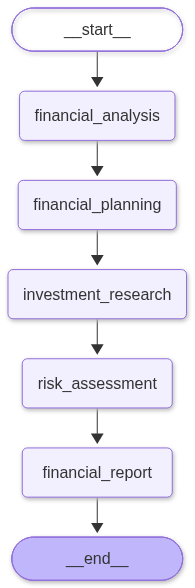

In [ ]:
from IPython.display import Image, display

display(
    Image(
        financial_assistant_graph.get_graph().draw_mermaid_png()
    )
)

Cell 94 — Integration consistency checks

In [ ]:
import math

# Retrieve final workflow outputs
final_summary = financial_assistant_result["financial_summary"]
final_planning = financial_assistant_result["planning_results"]
final_research = financial_assistant_result["investment_research_result"]
final_risk = financial_assistant_result["risk_assessment_result"]
final_report = financial_assistant_result["financial_report_result"]

# 1. Verify financial calculations
assert math.isclose(
    float(final_summary["total_income"]), 65000, abs_tol=0.01
)

assert math.isclose(
    float(final_summary["total_expenses"]), 32399, abs_tol=0.01
)

assert math.isclose(
    float(final_summary["total_investments"]), 3000, abs_tol=0.01
)

assert math.isclose(
    float(final_summary["cash_surplus"]), 29601, abs_tol=0.01
)

# 2. Verify emergency fund information
assert "emergency_fund_plan" in final_planning

assert math.isclose(
    float(final_planning["emergency_fund_plan"]["current_amount"]),
    30000,
    abs_tol=0.01
)

# 3. Verify investment research
assert "research_output" in final_research
assert "platform_evidence" in final_research

# 4. Verify risk assessment
assert final_risk is not None

# 5. Verify final report
assert final_report.executive_summary.strip()
assert final_report.recommended_actions

# 6. Verify report contains expected financial figures
report_text = financial_assistant_result["financial_report_markdown"]

assert "65,000.00" in report_text
assert "32,399.00" in report_text
assert "29,601.00" in report_text

print("All integration consistency checks passed!")
print("Financial calculations: Verified")
print("Financial planning: Verified")
print("Investment research: Verified")
print("Risk assessment: Verified")
print("Financial report: Verified")

All integration consistency checks passed!
Financial calculations: Verified
Financial planning: Verified
Investment research: Verified
Risk assessment: Verified
Financial report: Verified
